# Configuración de la radio definida por Software

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, find_peaks
from numpy.lib.stride_tricks import sliding_window_view
from pathlib import Path
from datetime import datetime, timezone


## Crear señal y metodos de deteccion


In [2]:
#------------------- LoRa preamble transmitter/receiver -------------------
SF_LORA = 8
BW_LORA = float(2_000_000)
FS_LORA = float(2_000_000)
N_LORA = int(2**SF_LORA)
k_lora = np.arange(N_LORA)

mensaje = 'hola mundo'
bytes_enviados = mensaje.encode('ascii')

def modular_simbolo(valor):
    if not 0 <= valor < N_LORA:
        raise ValueError('Símbolo fuera de rango')
    fase_discreta = ((valor+k_lora) % N_LORA)*k_lora/N_LORA
    return np.exp(2j*np.pi*fase_discreta)/np.sqrt(N_LORA)


# 8 símbolos completos ascendentes + 2 símbolos y 1/4 descendentes.
upchirp_lora = np.exp(1j * 2 * np.pi * k_lora**2 / N_LORA)
downchirp_lora = np.conj(upchirp_lora)
tx_preamble = np.concatenate([
    *([upchirp_lora] * 8),
    downchirp_lora,
    downchirp_lora,
    downchirp_lora[:N_LORA // 4],
])
# payload 10 simbolos en modulacion lora 'hola mundo'
payload = np.concatenate([np.sqrt(N_LORA) * modular_simbolo(v) for v in bytes_enviados])
silencio = np.zeros(N_LORA)  # un símbolo de silencio antes de la trama
# juntar todo en misma señal y normalizar
tx_signal = np.concatenate([tx_preamble, payload])
tx_signal = tx_signal / np.max(np.abs(tx_signal))
tx_signal = np.concatenate([silencio, tx_signal])
print(f'Preambulo: 8 upchirps + 2.25 downchirps + 10 simbolos payload; N={N_LORA} muestras/simbolo; {len(tx_preamble)} muestras')

def _chirp_peak_ratio(segmento, referencia):
    espectro = np.fft.fft(segmento * np.conj(referencia))
    potencia = np.abs(espectro)**2
    return float(np.max(potencia) / (np.mean(potencia) + np.finfo(float).eps))

def detectar_preambulo_original(rx, upchirp, downchirp, n_up=8):
    n = len(upchirp)
    longitud = n * (n_up + 2) + n // 4
    if len(rx) < longitud:
        raise ValueError('La captura no contiene suficientes muestras para el preámbulo')

    # Se prueban todas las fases de símbolo; así no se exige sincronismo externo.
    mejor_inicio, mejor_puntaje = None, -np.inf
    for inicio in range(n):
        up_scores = [
            _chirp_peak_ratio(rx[inicio + i*n:inicio + (i+1)*n], upchirp)
            for i in range(n_up)
        ]
        down_scores = [
            _chirp_peak_ratio(rx[inicio + i*n:inicio + (i+1)*n], downchirp)
            for i in range(n_up, n_up + 2)
        ]
        puntaje = float(np.mean(up_scores) + np.mean(down_scores))
        if puntaje > mejor_puntaje:
            mejor_inicio, mejor_puntaje = inicio, puntaje

    inicio = int(mejor_inicio)
    up_scores = np.array([
        _chirp_peak_ratio(rx[inicio + i*n:inicio + (i+1)*n], upchirp)
        for i in range(n_up)
    ])
    down_scores = np.array([
        _chirp_peak_ratio(rx[inicio + i*n:inicio + (i+1)*n], downchirp)
        for i in range(n_up, n_up + 2)
    ])
    cuarto_down = rx[inicio + (n_up + 2)*n:inicio + longitud]
    cuarto_score = _chirp_peak_ratio(cuarto_down, downchirp[:n // 4])
    detectado = (np.mean(up_scores) > 5) and (np.mean(down_scores) > 5) and (cuarto_score > 1)
    return {
        'detectado': bool(detectado),
        'inicio_muestra': inicio,
        'puntaje_upchirps': up_scores,
        'puntaje_downchirps': down_scores,
        'puntaje_downchirp_1_4': cuarto_score,
    }



Preambulo: 8 upchirps + 2.25 downchirps + 10 simbolos payload; N=256 muestras/simbolo; 2624 muestras


## Análisis preliminar de TX y de la normalización

En esta versión se conserva tu elección: `upchirp_lora` y `downchirp_lora` llevan `1/√N_LORA`; el payload se multiplica por `√N_LORA` después de `modular_simbolo` y queda con módulo 1. Con `N_LORA=256`, los chirps de cabecera tienen módulo **0,0625** y energía 1; cada símbolo del payload tiene módulo **1** y energía 256. El salto de potencia es **24,1 dB**. El gráfico de TX permite verlo. La correlación normalizada no cambia por una escala global, pero un preámbulo 16 veces menor que el payload puede ser más difícil de recibir y puede mover el AGC al llegar al payload.

La señal preparada es internamente consistente con su propio demodulador: el upchirp es el símbolo cero y la FFT dechirpeada de TX recupera `hola mundo`. Su fórmula discreta repite media rampa y puede crear ambigüedad de tiempo; no comprueba compatibilidad con LoRa estándar de otro equipo. La captura real previa reveló además un problema independiente en el tamaño efectivo del buffer TX, explicado al final del notebook.


Muestras: silencio 256 | preámbulo 2624 | payload 2560 | TX total 5440
Potencia media por muestra: up=1.000, down=1.000, cuarto=1.000, payload=1.000
Energía por chirp completo: 256.0; energía del cuarto: 64.0
Desnivel de potencia payload/preámbulo: 0.0 dB
Bytes TX verificados por dechirp + FFT: b'hola mundo'
Máxima diferencia entre las dos mitades del upchirp: 1.6660837689400692e-13
Diferencia al normalizar toda la trama por 1/√N y reescalar: 0.0


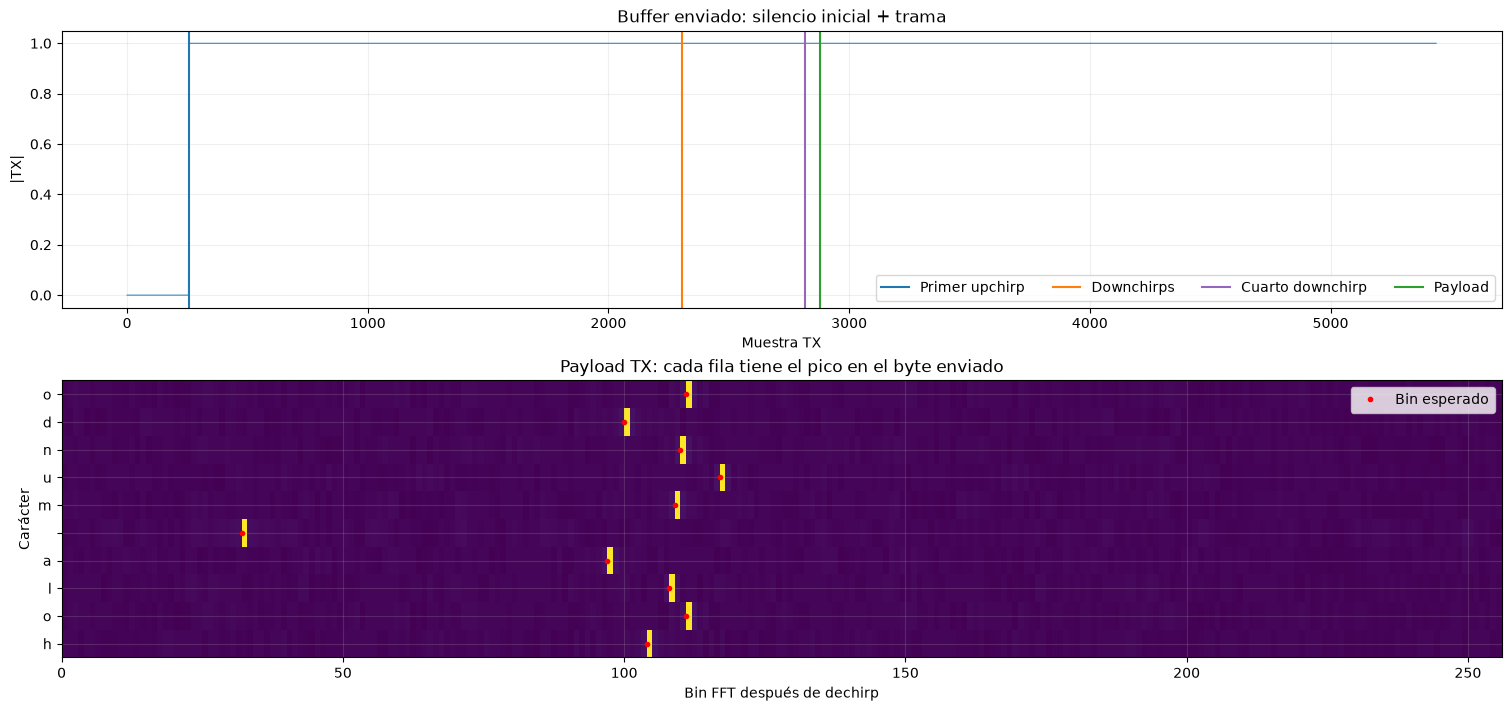

In [3]:
trama_tx = tx_signal[N_LORA:]
trama_unitaria = np.concatenate([tx_preamble, payload]) / np.sqrt(N_LORA)
trama_unitaria_reescalada = trama_unitaria / np.max(np.abs(trama_unitaria))
simbolos_tx = np.fft.fft(payload.reshape(-1, N_LORA) * np.conj(upchirp_lora), axis=1)
bytes_tx_verificados = bytes(np.argmax(np.abs(simbolos_tx), axis=1).tolist())
print('Muestras: silencio', len(silencio), '| preámbulo', len(tx_preamble),
      '| payload', len(payload), '| TX total', len(tx_signal))
print('Potencia media por muestra: up=%.3f, down=%.3f, cuarto=%.3f, payload=%.3f' % (
    np.mean(abs(upchirp_lora)**2), np.mean(abs(downchirp_lora)**2),
    np.mean(abs(downchirp_lora[:N_LORA//4])**2), np.mean(abs(payload)**2)))
print('Energía por chirp completo: %.1f; energía del cuarto: %.1f' % (
    np.sum(abs(upchirp_lora)**2), np.sum(abs(downchirp_lora[:N_LORA//4])**2)))
print('Desnivel de potencia payload/preámbulo: %.1f dB' % (
    10*np.log10(np.mean(abs(payload)**2)/np.mean(abs(upchirp_lora)**2))))
print('Bytes TX verificados por dechirp + FFT:', bytes_tx_verificados)
print('Máxima diferencia entre las dos mitades del upchirp:',
      np.max(abs(upchirp_lora[:N_LORA//2] - upchirp_lora[N_LORA//2:])))
print('Diferencia al normalizar toda la trama por 1/√N y reescalar:',
      np.max(abs(trama_unitaria_reescalada - trama_tx)))

fig, ax = plt.subplots(2, 1, figsize=(15, 7), constrained_layout=True)
ax[0].plot(np.abs(tx_signal), lw=0.7)
ax[0].axvline(N_LORA, color='tab:blue', label='Primer upchirp')
ax[0].axvline(N_LORA + 8*N_LORA, color='tab:orange', label='Downchirps')
ax[0].axvline(N_LORA + 10*N_LORA, color='tab:purple', label='Cuarto downchirp')
ax[0].axvline(N_LORA + len(tx_preamble), color='tab:green', label='Payload')
ax[0].set(xlabel='Muestra TX', ylabel='|TX|', title='Buffer enviado: silencio inicial + trama')
ax[0].legend(ncol=4)
ax[1].imshow(20*np.log10(np.abs(simbolos_tx) + 1e-12), aspect='auto', origin='lower',
             extent=(0, N_LORA, -0.5, len(bytes_enviados)-0.5), cmap='viridis')
ax[1].plot(list(bytes_enviados), np.arange(len(bytes_enviados)), 'r.', label='Bin esperado')
ax[1].set(xlabel='Bin FFT después de dechirp', ylabel='Carácter',
          title='Payload TX: cada fila tiene el pico en el byte enviado')
ax[1].set_yticks(np.arange(len(bytes_enviados)), list(mensaje))
ax[1].legend()
for panel in ax:
    panel.grid(alpha=0.2)
plt.show()


## Detección temporal y diagnóstico espectral

La sincronización principal vuelve a ser por **correlación en tiempo**. El detector FFT de Chesta queda disponible sólo como diagnóstico independiente. Con TX cíclica, el buffer `silencio + trama` se repite; por eso el inicio puede caer en cualquier muestra de RX. La fórmula discreta del chirp tiene una ambigüedad de 64 muestras: comprobar por separado los dos downchirps y el cuarto final ayuda a descartarla.


In [4]:
def _metricas_fft(rx, referencia, tamano_lote=512):
    """Pico/energía media y bin dominante para cada ventana completa."""
    ventanas = sliding_window_view(np.asarray(rx), len(referencia))
    razones = np.empty(len(ventanas))
    bins = np.empty(len(ventanas), dtype=int)
    for base in range(0, len(ventanas), tamano_lote):
        espectro = np.fft.fft(ventanas[base:base + tamano_lote] * np.conj(referencia), axis=1)
        potencia = np.abs(espectro) ** 2
        bins[base:base + tamano_lote] = np.argmax(potencia, axis=1)
        razones[base:base + tamano_lote] = np.max(potencia, axis=1) / (
            np.mean(potencia, axis=1) + np.finfo(float).eps
        )
    return razones, bins


def detectar_preambulo_lora(rx, upchirp, downchirp, n_up=8, umbral_fft=20):
    """Busca cabeceras completas en toda la captura mediante dechirp + FFT."""
    rx = np.asarray(rx)
    n = len(upchirp)
    largo = (n_up + 2) * n + n // 4
    if len(rx) < largo:
        raise ValueError('La captura no contiene un preámbulo completo')
    cantidad = len(rx) - largo + 1
    razon_up, bin_up = _metricas_fft(rx, upchirp)
    razon_down, bin_down = _metricas_fft(rx, downchirp)
    up = np.stack([razon_up[i*n:i*n + cantidad] for i in range(n_up)])
    down = np.stack([razon_down[i*n:i*n + cantidad] for i in range(n_up, n_up + 2)])
    # Exigir ambos downchirps evita elegir un tramo cualquiera de upchirps repetidos.
    estructura = np.minimum(np.percentile(up, 25, axis=0), np.min(down, axis=0))
    bin_u = bin_up[(n_up - 1)*n:(n_up - 1)*n + cantidad]
    bin_d1 = bin_down[n_up*n:n_up*n + cantidad]
    bin_d2 = bin_down[(n_up + 1)*n:(n_up + 1)*n + cantidad]
    distancia = lambda a, b: np.abs((a - b + n//2) % n - n//2)
    discrepancia = np.maximum(distancia(bin_u, bin_d1), distancia(bin_d1, bin_d2))
    puntajes = estructura / (1 + discrepancia)
    picos, _ = find_peaks(puntajes, height=umbral_fft)
    # find_peaks no incluye los extremos de la captura.
    picos = np.unique(np.r_[picos, 0, cantidad - 1])
    picos = picos[puntajes[picos] >= umbral_fft]
    detecciones = []
    for inicio in picos[np.argsort(puntajes[picos])[::-1]]:
        cuarto = rx[inicio + (n_up + 2)*n:inicio + largo]
        razon_cuarto = _chirp_peak_ratio(cuarto, downchirp[:n//4])
        if razon_cuarto >= 6 and np.count_nonzero(up[:, inicio] >= umbral_fft) >= n_up - 1:
            if all(abs(inicio - anterior) >= largo for anterior in detecciones):
                detecciones.append(int(inicio))
    detecciones.sort()
    mejor = max(detecciones, key=lambda i: puntajes[i]) if detecciones else None
    return {
        'detectado': mejor is not None,
        'inicio_muestra': mejor,
        'inicios': detecciones,
        'puntajes': puntajes,
        'puntaje_maximo': float(np.max(puntajes)),
        'puntaje_upchirps': up[:, mejor] if mejor is not None else None,
        'puntaje_downchirps': down[:, mejor] if mejor is not None else None,
        'puntaje_downchirp_1_4': (
            _chirp_peak_ratio(rx[mejor + (n_up + 2)*n:mejor + largo], downchirp[:n//4])
            if mejor is not None else None
        ),
    }


## Correlación temporal de toda la cabecera y de sus partes

La correlación directa de clase permanece para comparar. En RF, un corrimiento de frecuencia puede cancelar su suma compleja. La diferencial usa productos de muestras vecinas y tolera ese corrimiento. Se calculan además las curvas de 8 upchirps, downchirp 1, downchirp 2 y el cuarto final. El detector busca **máximos locales**, exige todas las partes y la cabecera diferencial, y muestra los cinco mayores aun si ninguno cruza el umbral.

La curva «decisión» es el mínimo entre las cuatro partes y la cabecera diferencial; los umbrales se aplican a ella. El producto sólo ordena los máximos locales.

El umbral exploratorio baja de `0,80` a **`0,45`** por correlación. Una marca «fuerte» conserva `0,80`. Una marca exploratoria es una hipótesis de inicio, no una trama verificada: al bajar el umbral puede aparecer una detección desplazada si falta el cuarto de downchirp. Los gráficos de cada parte y los bytes RX permiten identificar ese caso.


In [5]:
def correlacion_normalizada(bloque, plantilla):
    bloque = np.asarray(bloque)
    plantilla = np.asarray(plantilla)
    numerador = np.abs(correlate(bloque, plantilla, mode='valid', method='fft'))
    energia = np.convolve(np.abs(bloque)**2, np.ones(len(plantilla)), mode='valid')
    return numerador / np.sqrt(np.maximum(energia, 0) * np.sum(np.abs(plantilla)**2) + np.finfo(float).eps)


def detectar_por_tiempo(rx, plantilla, n, umbral=0.45, umbral_fuerte=0.80):
    rx = np.asarray(rx)
    largo = len(plantilla)
    if len(rx) < largo:
        raise ValueError('La captura no contiene una cabecera completa')
    candidatos = len(rx) - largo + 1
    rx_d = rx[1:] * np.conj(rx[:-1])

    def tramo(inicio, fin):
        tx = plantilla[inicio:fin]
        tx_d = tx[1:] * np.conj(tx[:-1])
        return correlacion_normalizada(rx_d, tx_d)[inicio:inicio + candidatos]

    arriba = tramo(0, 8*n)
    down_1 = tramo(8*n, 9*n)
    down_2 = tramo(9*n, 10*n)
    down_cuarto = tramo(10*n, largo)
    combinada = np.minimum.reduce([arriba, down_1, down_2, down_cuarto])
    directa = correlacion_normalizada(rx, plantilla)
    plantilla_d = plantilla[1:] * np.conj(plantilla[:-1])
    diferencial = correlacion_normalizada(rx_d, plantilla_d)

    decision = np.minimum(combinada, diferencial)
    puntaje_final = combinada * diferencial
    picos, _ = find_peaks(puntaje_final)
    picos = np.unique(np.r_[picos, 0, candidatos - 1])
    mayores = []
    for i in picos[np.argsort(puntaje_final[picos])[::-1]]:
        if all(abs(i - j) >= largo for j in mayores):
            mayores.append(int(i))
        if len(mayores) == 5:
            break
    inicios = [i for i in mayores if decision[i] >= umbral]
    confirmados = [i for i in inicios if decision[i] >= umbral_fuerte]
    mejor = inicios[0] if inicios else None
    mejor_candidato = mayores[0]
    return {'detectado': mejor is not None, 'inicio_muestra': mejor, 'inicios': inicios,
            'confirmados': confirmados, 'candidatos_mayores': mayores,
            'mejor_candidato': mejor_candidato,
            'directa': directa, 'diferencial': diferencial,
            'up': arriba, 'down_1': down_1, 'down_2': down_2,
            'down_cuarto': down_cuarto, 'combinada': combinada,
            'puntaje_final': puntaje_final, 'decision': decision, 'umbral': umbral,
            'umbral_fuerte': umbral_fuerte}


def refinar_inicio_directo(resultado, inicio, radio=4, minimo_directa=0.50):
    """Ajusta hasta 4 muestras con la correlación directa, si tiene un pico claro."""
    izquierda = max(0, inicio - radio)
    derecha = min(len(resultado['directa']), inicio + radio + 1)
    refinado = izquierda + int(np.argmax(resultado['directa'][izquierda:derecha]))
    return refinado if resultado['directa'][refinado] >= minimo_directa else inicio


## Lectura y comprobación de la trama

El payload se demodula usando el inicio **temporal**. Se estima el corrimiento de frecuencia con los upchirps y se corrige antes de la FFT de cada byte. Se informa si los bytes recibidos son exactamente `hola mundo`. La forma de onda recibida no puede ser idéntica muestra por muestra a TX por ruido, ganancia y fase del canal: para compararla se compensan frecuencia y ganancia compleja, y se grafica el error residual.


In [6]:
def leer_payload_sdr(rx, inicio, upchirp, cantidad):
    n = len(upchirp)
    comienzo = inicio + len(tx_preamble)
    fin = comienzo + cantidad*n
    if fin > len(rx):
        return None, None
    pre = np.asarray(rx[inicio:inicio + 8*n]).reshape(8, n) * np.conj(upchirp)
    fase = np.sum(pre[:, 1:] * np.conj(pre[:, :-1]))
    offset = np.angle(fase) / (2*np.pi)  # ciclos por muestra, estimación gruesa
    datos = np.asarray(rx[comienzo:fin]).reshape(cantidad, n)
    indices = comienzo - inicio + np.arange(cantidad*n)
    corregido = datos.reshape(-1) * np.exp(-2j*np.pi*offset*indices)
    espectros = np.fft.fft(corregido.reshape(cantidad, n) * np.conj(upchirp), axis=1)
    return bytes(np.argmax(np.abs(espectros), axis=1).tolist()), offset * FS_LORA




## Comprobación reproducible sin SDR

La prueba inserta una trama con inicio no alineado al símbolo, ruido y corrimiento de 3,2 kHz. Comprueba el inicio por correlación temporal, la ausencia de detección en ruido solo, la repetición cíclica y la igualdad del payload. También se verifica una trama deliberadamente incompleta: puede crear un candidato exploratorio desplazado, pero no una detección fuerte. La figura guardada en esta celda está etiquetada como **simulación**; la captura real se grafica al final del notebook.


TX sin ruido: inicio temporal 256 | decisión 1.0
Inicio real / temporal / FFT: 387 387 387
TX/RX payload: b'hola mundo' b'hola mundo' | iguales: True
Ruido solo: sin detección | TX cíclica: inicio 4749
Candidatos temporales mayores: [387, 4253]
Sin cuarto downchirp: candidatos exploratorios [323] | fuertes: []


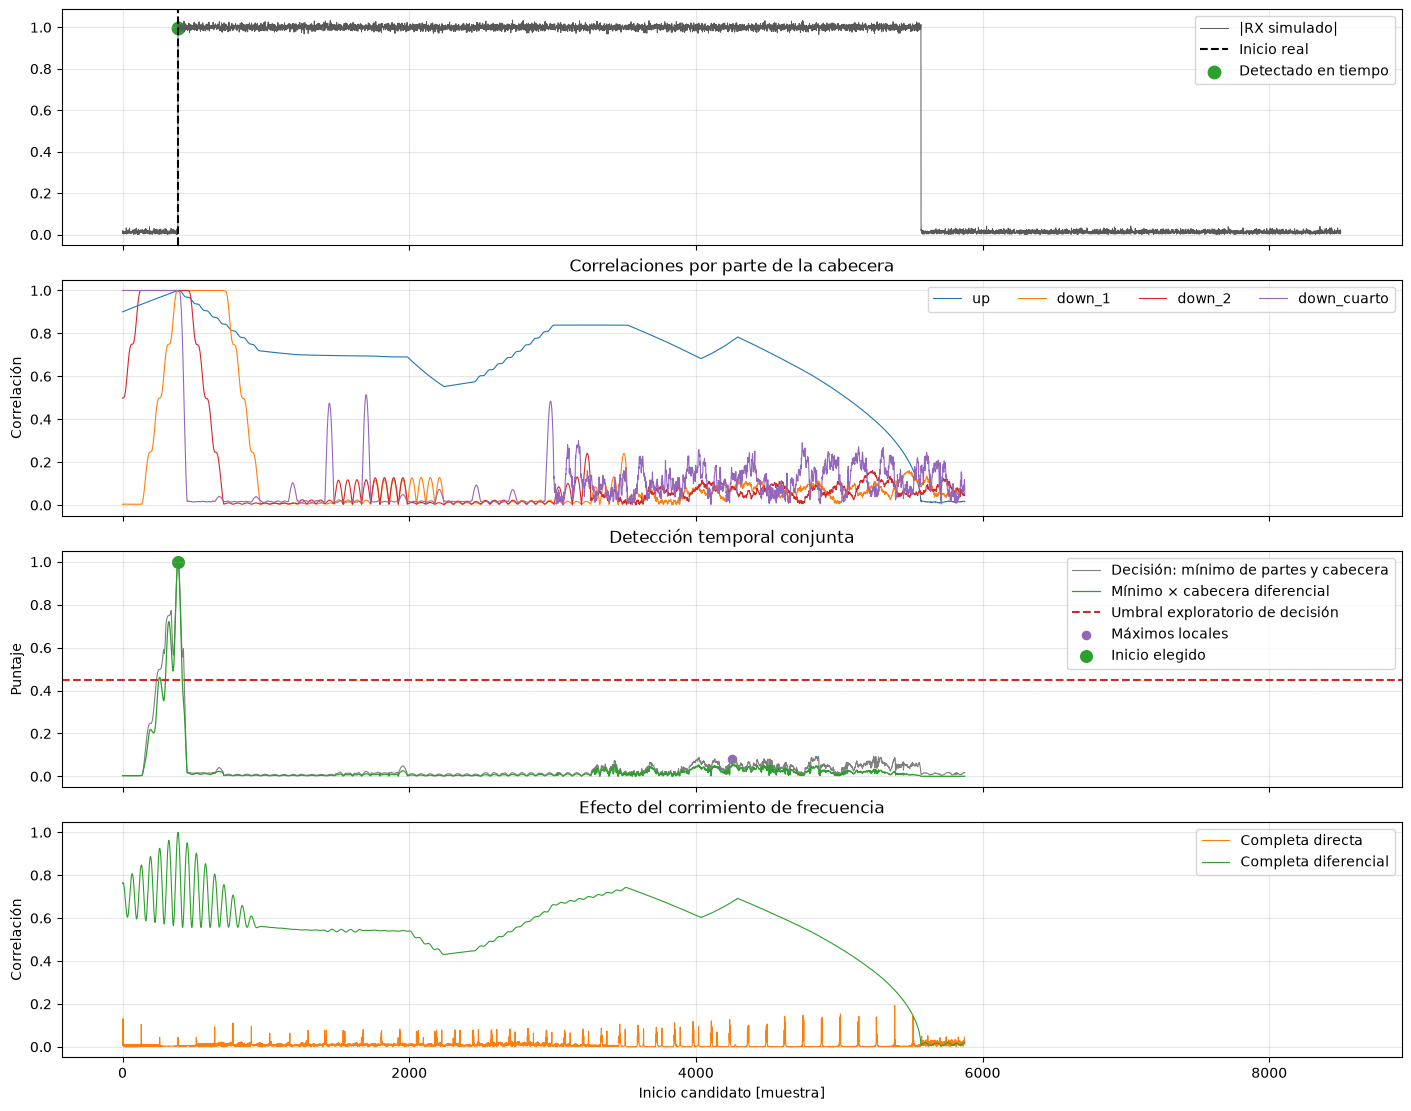

In [7]:
rng = np.random.default_rng(2026)
inicio_prueba = 387
bloque_prueba = 0.01 * (rng.normal(size=8500) + 1j*rng.normal(size=8500))
trama_prueba = tx_signal[N_LORA:]  # silencio sólo al principio del buffer TX
desfase_hz = 3200
indices_prueba = np.arange(len(trama_prueba))
bloque_prueba[inicio_prueba:inicio_prueba + len(trama_prueba)] += (
    trama_prueba * np.exp(2j*np.pi*desfase_hz*indices_prueba/FS_LORA)
)
prueba_tx_limpio = detectar_por_tiempo(tx_signal, tx_preamble, N_LORA)
assert prueba_tx_limpio['inicio_muestra'] == N_LORA
assert prueba_tx_limpio['decision'][N_LORA] > 0.99
print('TX sin ruido: inicio temporal', prueba_tx_limpio['inicio_muestra'],
      '| decisión', round(float(prueba_tx_limpio['decision'][N_LORA]), 3))
prueba_t = detectar_por_tiempo(bloque_prueba, tx_preamble, N_LORA)
prueba_fft = detectar_preambulo_lora(bloque_prueba, upchirp_lora, downchirp_lora)
prueba_bytes, _ = leer_payload_sdr(bloque_prueba, prueba_t['inicio_muestra'], upchirp_lora, len(bytes_enviados))
assert prueba_t['inicio_muestra'] == inicio_prueba
assert prueba_bytes == bytes_enviados
ruido_solo = 0.02 * (rng.normal(size=8500) + 1j*rng.normal(size=8500))
assert not detectar_por_tiempo(ruido_solo, tx_preamble, N_LORA)['detectado']
bloque_ciclico = np.tile(tx_signal, 3)[947:947 + 2*len(tx_signal)]
prueba_ciclica = detectar_por_tiempo(bloque_ciclico, tx_preamble, N_LORA)
inicio_ciclico = (N_LORA - 947) % len(tx_signal)
assert prueba_ciclica['inicios'] == [inicio_ciclico]
print('Inicio real / temporal / FFT:', inicio_prueba, prueba_t['inicio_muestra'], prueba_fft['inicio_muestra'])
print('TX/RX payload:', bytes_enviados, prueba_bytes, '| iguales:', prueba_bytes == bytes_enviados)
print('Ruido solo: sin detección | TX cíclica: inicio', prueba_ciclica['inicio_muestra'])
print('Candidatos temporales mayores:', prueba_t['candidatos_mayores'])
trama_incompleta = trama_prueba.copy()
trama_incompleta[10*N_LORA:len(tx_preamble)] = 0
bloque_incompleto = bloque_prueba.copy()
bloque_incompleto[inicio_prueba:inicio_prueba + len(trama_prueba)] -= (
    trama_prueba * np.exp(2j*np.pi*desfase_hz*indices_prueba/FS_LORA))
bloque_incompleto[inicio_prueba:inicio_prueba + len(trama_prueba)] += (
    trama_incompleta * np.exp(2j*np.pi*desfase_hz*indices_prueba/FS_LORA))
prueba_incompleta = detectar_por_tiempo(bloque_incompleto, tx_preamble, N_LORA)
assert not prueba_incompleta['confirmados']
print('Sin cuarto downchirp: candidatos exploratorios', prueba_incompleta['inicios'],
      '| fuertes:', prueba_incompleta['confirmados'])

fig, ax = plt.subplots(4, 1, figsize=(14, 11), sharex=True, constrained_layout=True)
ax[0].plot(np.abs(bloque_prueba), color='0.35', lw=0.7, label='|RX simulado|')
ax[0].axvline(inicio_prueba, color='black', ls='--', label='Inicio real')
ax[0].scatter(prueba_t['inicio_muestra'], np.abs(bloque_prueba[prueba_t['inicio_muestra']]),
              color='tab:green', s=80, label='Detectado en tiempo')
ax[0].legend()
for nombre, color in [('up', 'tab:blue'), ('down_1', 'tab:orange'),
                      ('down_2', 'tab:red'), ('down_cuarto', 'tab:purple')]:
    ax[1].plot(prueba_t[nombre], color=color, lw=0.8, label=nombre)
ax[1].set(ylabel='Correlación', title='Correlaciones por parte de la cabecera')
ax[1].legend(ncol=4)
ax[2].plot(prueba_t['decision'], color='0.5', lw=0.8, label='Decisión: mínimo de partes y cabecera')
ax[2].plot(prueba_t['puntaje_final'], color='tab:green', lw=0.9, label='Mínimo × cabecera diferencial')
ax[2].axhline(prueba_t['umbral'], color='tab:red', ls='--', label='Umbral exploratorio de decisión')
ax[2].scatter(prueba_t['candidatos_mayores'],
              prueba_t['decision'][prueba_t['candidatos_mayores']],
              color='tab:purple', s=35, label='Máximos locales')
ax[2].scatter(prueba_t['inicio_muestra'], prueba_t['decision'][prueba_t['inicio_muestra']],
              color='tab:green', s=70, label='Inicio elegido')
ax[2].set(ylabel='Puntaje', title='Detección temporal conjunta')
ax[2].legend()
ax[3].plot(prueba_t['directa'], color='tab:orange', lw=0.8, label='Completa directa')
ax[3].plot(prueba_t['diferencial'], color='tab:green', lw=0.8, label='Completa diferencial')
ax[3].set(xlabel='Inicio candidato [muestra]', ylabel='Correlación', title='Efecto del corrimiento de frecuencia')
ax[3].legend()
for a in ax:
    a.grid(alpha=0.3)
plt.show()


## 3. Configurar, transmitir y recibir con SDR

TX contiene **un símbolo de silencio inicial + preámbulo + payload** y el buffer cíclico debería repetir las 5440 muestras. La captura RX tendrá cuatro períodos completos para poder descartar un primer ciclo transitorio y comparar repeticiones.

**Falla encontrada en la corrida de 2026-11-16:** con la versión instalada de `pyadi-iio` y `libiio` v1, `adi.compat.compat_libiio_v1_tx._tx_init_channels` entrega a `iio.Block` el número de muestras como si fuera un número de bytes. El bloque real fue de 5440 bytes, es decir, sólo 1360 muestras IQ de 4 bytes. El RX repite ese prefijo de TX cada 1360 muestras; los downchirps y el payload no fueron transmitidos. La celda TX corrige localmente el tamaño del bloque y comprueba los bytes escritos, sin modificar la instalación de Python.

El cambio de amplitud que se hizo en el preámbulo se conserva: `1/√N_LORA` en upchirps y downchirps, mientras el payload queda en amplitud 1. Por eso la amplitud del preámbulo es 16 veces menor. Esta diferencia no explica el período de 1360 muestras, que aparece también en la captura anterior al cambio.


In [8]:
import adi
sdr = adi.Pluto('ip:192.168.1.34')
sdr.tx_destroy_buffer()
sdr.rx_destroy_buffer()
sdr.loopback = 0
# Esta tasa fija la duración física de cada muestra, tanto en TX como en RX.
sdr.sample_rate = FS_LORA # 2MS/s
sdr.tx_lo = 915_000_000
sdr.rx_lo = 915_000_000
sdr.tx_rf_bandwidth = 2_000_000
sdr.rx_rf_bandwidth = 2_000_000
sdr.tx_hardwaregain_chan0 = -50
sdr.gain_control_mode_chan0 = 'slow_attack'
sdr.rx_buffer_size = 4*len(tx_signal)  # cuatro períodos para comparar ciclos
sdr.tx_cyclic_buffer = True
# sdr._ctrl.context.set_timeout(0) # <- disable timeout if you want to use large buffer size


In [9]:
# TRANSMITIR: silencio inicial + trama completa, con buffer cíclico.
import iio
from types import MethodType

muestras_sdr = (tx_signal * (2**14-1)).astype(np.complex64)
rx_signal = None  # una falla de TX invalida la captura anterior del kernel
sdr.tx_destroy_buffer()

if hasattr(sdr, '_tx_buf_stream'):  # ruta libiio v1 instalada en esta computadora
    def _push_ciclico_completo(self, datos_intercalados):
        datos_bytes = bytearray(np.asarray(datos_intercalados).tobytes())
        if len(self._tx_block) != len(datos_bytes):
            self._tx_block = iio.Block(self._tx_buf_stream, len(datos_bytes))
        escritos = self._tx_block.write(datos_bytes)
        if escritos != len(datos_bytes):
            raise RuntimeError(f'TX incompleto: {escritos} de {len(datos_bytes)} bytes')
        self._tx_block.enqueue(None, True)
        self._tx_buf_stream.started = True
    sdr._tx_buffer_push = MethodType(_push_ciclico_completo, sdr)

sdr.tx(muestras_sdr)
if hasattr(sdr, '_tx_block') and sdr._tx_block is not None:
    bytes_tx = len(sdr._tx_block)
    bytes_esperados = len(muestras_sdr)*4  # I y Q de 16 bits
    if bytes_tx != bytes_esperados:
        raise RuntimeError(f'Buffer TX de {bytes_tx} bytes; esperados {bytes_esperados}')
    print(f'Buffer cíclico TX: {bytes_tx} bytes = {bytes_tx//4} muestras IQ')
print(f'TX preparado: {len(muestras_sdr)} muestras; {N_LORA} de silencio inicial, sin silencio final')


Buffer cíclico TX: 21760 bytes = 5440 muestras IQ
TX preparado: 5440 muestras; 256 de silencio inicial, sin silencio final


In [10]:
# Guardamos también la primera lectura para diagnosticar transitorios o AGC.
rx_primera = np.asarray(sdr.rx()).copy()
rx_signal = np.asarray(sdr.rx()).copy()
print('Muestras RX primera / análisis / esperadas:',
      len(rx_primera), len(rx_signal), sdr.rx_buffer_size)
if len(rx_signal) != sdr.rx_buffer_size:
    raise RuntimeError('Tamaño RX distinto del configurado; reiniciá y ejecutá las celdas en orden.')
carpeta_iq = Path('sdr_final') if Path('sdr_final').is_dir() else Path('.')
archivo_iq = (carpeta_iq / f"captura_chesta_{datetime.now(timezone.utc):%Y%m%dT%H%M%S_%fZ}.npz").resolve()
np.savez_compressed(archivo_iq, rx_signal=rx_signal, rx_primera=rx_primera,
                    tx_signal=tx_signal, fs=FS_LORA)
print('Captura IQ guardada en:', archivo_iq)
envolvente_rx = np.abs(rx_signal)
autocorr_rx = correlate(envolvente_rx - envolvente_rx.mean(),
                        envolvente_rx - envolvente_rx.mean(), mode='full', method='fft')[len(rx_signal)-1:]
periodo_rx = int(1000 + np.argmax(autocorr_rx[1000:len(tx_signal)+N_LORA]))
print('Período estimado de la envolvente RX:', periodo_rx,
      '| período esperado del buffer TX:', len(tx_signal))
if abs(periodo_rx - len(tx_signal)) > N_LORA:
    print('ADVERTENCIA: RX no repite el buffer TX completo; revisar TX antes del umbral.')


Muestras RX primera / análisis / esperadas: 21760 21760 21760
Captura IQ guardada en: /home/valentino/Documentos/ChatGPT/procesamiento estocastico de señales/sdr_final/captura_chesta_20261116T021420_874793Z.npz
Período estimado de la envolvente RX: 5440 | período esperado del buffer TX: 5440


In [11]:
# Cerrar el SDR inmediatamente después de guardar la captura IQ.
# No enviar otro sdr.tx(np.zeros(...)): en esta ruta libiio v1 esa secuencia
# podía terminar el kernel después de destruir el buffer cíclico.
try:
    sdr.tx_hardwaregain_chan0 = -89
    sdr.tx_lo = int(2400e6)
finally:
    try:
        sdr.tx_destroy_buffer()
    finally:
        try:
            sdr.rx_destroy_buffer()
        finally:
            # El método agregado en TX referencia al propio objeto SDR.
            if '_tx_buffer_push' in getattr(sdr, '__dict__', {}):
                del sdr._tx_buffer_push
            del sdr
print('SDR cerrado: buffers TX/RX liberados y objeto eliminado; IQ guardado para el análisis.')


SDR cerrado: buffers TX/RX liberados y objeto eliminado; IQ guardado para el análisis.


## Detectar el inicio en la captura SDR

La **curva gris «decisión»** es el mínimo de cinco correlaciones normalizadas: los 8 upchirps, cada uno de los 2 downchirps, el cuarto downchirp y la cabecera completa diferencial. La línea roja de 0,45 marca hipótesis exploratorias; la violeta de 0,80 marca las fuertes. La curva verde, producto del mínimo de las partes por la cabecera, sólo **ordena** los máximos locales. Los cinco mayores se dibujan aunque estén por debajo de ambos umbrales. Ningún punto por debajo de 0,45 es una detección válida.

El método original y el de FFT permanecen para comparar. El original sólo examina las primeras 256 fases de símbolo y su `True` en la captura anterior no verificó la trama completa. La lectura de bytes de un candidato sin confirmar es únicamente un diagnóstico: no prueba recepción del payload. La correlación diferencial suele dar un máximo ancho y, en la captura nueva, adelanta el inicio dos muestras. Si hay un pico directo claro a ±4 muestras, se usa ese punto para leer el payload y comparar la forma de onda.

Después de guardar IQ, la celda siguiente atenúa y retunea TX, libera los buffers TX/RX y elimina el objeto SDR antes de analizar la captura. No se envía un nuevo buffer de ceros: esa operación después de destruir el bloque cíclico se había asociado al cierre asíncrono del kernel. La nueva secuencia de cierre requiere verificarse en una ejecución con el Pluto; las figuras guardadas corresponden a la captura anterior a este ajuste.


In [12]:
resultado_original = detectar_preambulo_original(rx_signal, upchirp_lora, downchirp_lora)
resultado_fft = detectar_preambulo_lora(rx_signal, upchirp_lora, downchirp_lora)
print('Fuente RX:', archivo_iq if 'archivo_iq' in globals() else 'rx_signal en memoria')
print('Método original sobre RX real (primeras 256 posiciones):', resultado_original['detectado'], resultado_original['inicio_muestra'])
print('FFT auxiliar:', resultado_fft['detectado'], resultado_fft['inicios'])


Fuente RX: /home/valentino/Documentos/ChatGPT/procesamiento estocastico de señales/sdr_final/captura_chesta_20261116T021420_874793Z.npz
Método original sobre RX real (primeras 256 posiciones): False 223
FFT auxiliar: True [3550, 8990, 14430]


In [13]:
UMBRAL_EXPLORATORIO = 0.45
UMBRAL_FUERTE = 0.80
resultado_tiempo = detectar_por_tiempo(
    rx_signal, tx_preamble, N_LORA,
    umbral=UMBRAL_EXPLORATORIO, umbral_fuerte=UMBRAL_FUERTE)
print('Detecciones exploratorias:', resultado_tiempo['inicios'])
print('Detecciones fuertes (gruesas):', resultado_tiempo['confirmados'])
print('Inicios refinados por correlación directa:',
      [(i, refinar_inicio_directo(resultado_tiempo, i))
       for i in resultado_tiempo['confirmados']])
print('Cinco máximos principales (muestra, decisión, producto):',
      [(i, round(float(resultado_tiempo['decision'][i]), 3),
        round(float(resultado_tiempo['puntaje_final'][i]), 3))
       for i in resultado_tiempo['candidatos_mayores']])
print('Máximos: directa = %.3f, diferencial = %.3f, final = %.3f' % (
    resultado_tiempo['directa'].max(), resultado_tiempo['diferencial'].max(),
    resultado_tiempo['puntaje_final'].max()))
i = resultado_tiempo['mejor_candidato']
print('Mejor candidato:', i, '| exploratorio:', i in resultado_tiempo['inicios'],
      '| fuerte:', i in resultado_tiempo['confirmados'])
print('En ese candidato: up=%.3f, down1=%.3f, down2=%.3f, cuarto=%.3f, completa=%.3f, decisión=%.3f' % (
    resultado_tiempo['up'][i], resultado_tiempo['down_1'][i],
    resultado_tiempo['down_2'][i], resultado_tiempo['down_cuarto'][i],
    resultado_tiempo['diferencial'][i], resultado_tiempo['decision'][i]))


Detecciones exploratorias: [8990, 3550, 14430]
Detecciones fuertes (gruesas): [8990, 3550, 14430]
Inicios refinados por correlación directa: [(8990, 8990), (3550, 3550), (14430, 14430)]
Cinco máximos principales (muestra, decisión, producto): [(8990, 0.971, 0.944), (3550, 0.97, 0.943), (14430, 0.97, 0.943), (17474, 0.121, 0.08), (11786, 0.073, 0.05)]
Máximos: directa = 0.942, diferencial = 0.972, final = 0.944
Mejor candidato: 8990 | exploratorio: True | fuerte: True
En ese candidato: up=0.972, down1=0.971, down2=0.971, cuarto=0.986, completa=0.972, decisión=0.971


In [14]:
candidatos_lectura = (resultado_tiempo['confirmados'] or
                      resultado_tiempo['candidatos_mayores'])
inicios_completos = [(i, refinar_inicio_directo(resultado_tiempo, i))
                     for i in candidatos_lectura
                     if refinar_inicio_directo(resultado_tiempo, i) + len(tx_preamble) + len(payload) <= len(rx_signal)]
comparacion = None
if inicios_completos:
    inicio_grueso, inicio_rx = inicios_completos[0]
    bytes_recibidos, offset_hz = leer_payload_sdr(rx_signal, inicio_rx, upchirp_lora, len(bytes_enviados))
    print('Inicio grueso / refinado usado para lectura:', inicio_grueso, inicio_rx,
          '| exploratorio:', inicio_grueso in resultado_tiempo['inicios'],
          '| fuerte:', inicio_grueso in resultado_tiempo['confirmados'])
    print(f'Corrección estimada desde upchirps para demodular bytes: {offset_hz:.0f} Hz')
    if inicio_grueso not in resultado_tiempo['confirmados']:
        print('ATENCIÓN: lectura sobre candidato no confirmado; bytes RX sólo diagnósticos.')
    print('Bytes TX:', bytes_enviados, '| bytes RX:', bytes_recibidos)
    print('Payload exactamente igual:', bytes_recibidos == bytes_enviados)
    print('Texto RX:', bytes_recibidos.decode('ascii', errors='replace'))

    if inicio_grueso in resultado_tiempo['inicios']:
        trama_tx = tx_signal[N_LORA:]
        trama_rx = rx_signal[inicio_rx:inicio_rx + len(trama_tx)]
        # Para comparar formas de onda, estimar la rotación del producto RX·conj(TX).
        # El estimador de dechirp puede confundir ±1 muestra con varios kHz.
        fft_offset = 8 * 2**int(np.ceil(np.log2(len(trama_tx))))
        producto_tx_rx = trama_rx * np.conj(trama_tx)
        bin_offset = np.argmax(np.abs(np.fft.fft(producto_tx_rx, n=fft_offset)))
        offset_forma_hz = np.fft.fftfreq(fft_offset, d=1/FS_LORA)[bin_offset]
        corregida = trama_rx * np.exp(-2j*np.pi*offset_forma_hz*np.arange(len(trama_tx))/FS_LORA)
        print(f'Rotación estimada para comparar forma de onda: {offset_forma_hz:.0f} Hz')
        ganancia = np.vdot(trama_tx, corregida) / np.vdot(trama_tx, trama_tx)
        rx_alineada = corregida / ganancia if abs(ganancia) > 1e-12 else np.zeros_like(corregida)
        error = rx_alineada - trama_tx
        evm = np.linalg.norm(error) / np.linalg.norm(trama_tx)
        similitud = abs(np.vdot(trama_tx, corregida)) / (np.linalg.norm(trama_tx) * np.linalg.norm(corregida) + 1e-12)
        comparacion = {'tx': trama_tx, 'rx': rx_alineada, 'error': error,
                       'evm': evm, 'similitud': similitud}
        print(f'Similitud de forma de onda: {similitud:.3f} | error RMS relativo: {evm:.3f}')

        potencia_rx_pre = np.mean(np.abs(trama_rx[:8*N_LORA])**2)
        potencia_rx_payload = np.mean(np.abs(trama_rx[len(tx_preamble):])**2)
        print(f'Desnivel RX preámbulo/payload: {10*np.log10((potencia_rx_pre + 1e-12)/(potencia_rx_payload + 1e-12)):.1f} dB')
    else:
        print('Candidato bajo umbral: se omite la comparación de forma de onda.')
else:
    print('No hay una trama completa detectada para comparar el payload.')


Inicio grueso / refinado usado para lectura: 8990 8990 | exploratorio: True | fuerte: True
Corrección estimada desde upchirps para demodular bytes: -2743 Hz
Bytes TX: b'hola mundo' | bytes RX: b'hola mundo'
Payload exactamente igual: True
Texto RX: hola mundo
Rotación estimada para comparar forma de onda: 0 Hz
Similitud de forma de onda: 0.942 | error RMS relativo: 0.357
Desnivel RX preámbulo/payload: -0.0 dB


## Vistas I/Q, espectro y frecuencia instantánea

Si no hay inicio temporal por encima del umbral exploratorio, RX se grafica desde la muestra cero. Cuando hay inicio, se usa el ajuste fino para alinear TX/RX. No se presenta el máximo débil como si estuviera alineado al comienzo del preámbulo. Los máximos débiles sí aparecen, con sus muestras exactas, en la figura de correlaciones.


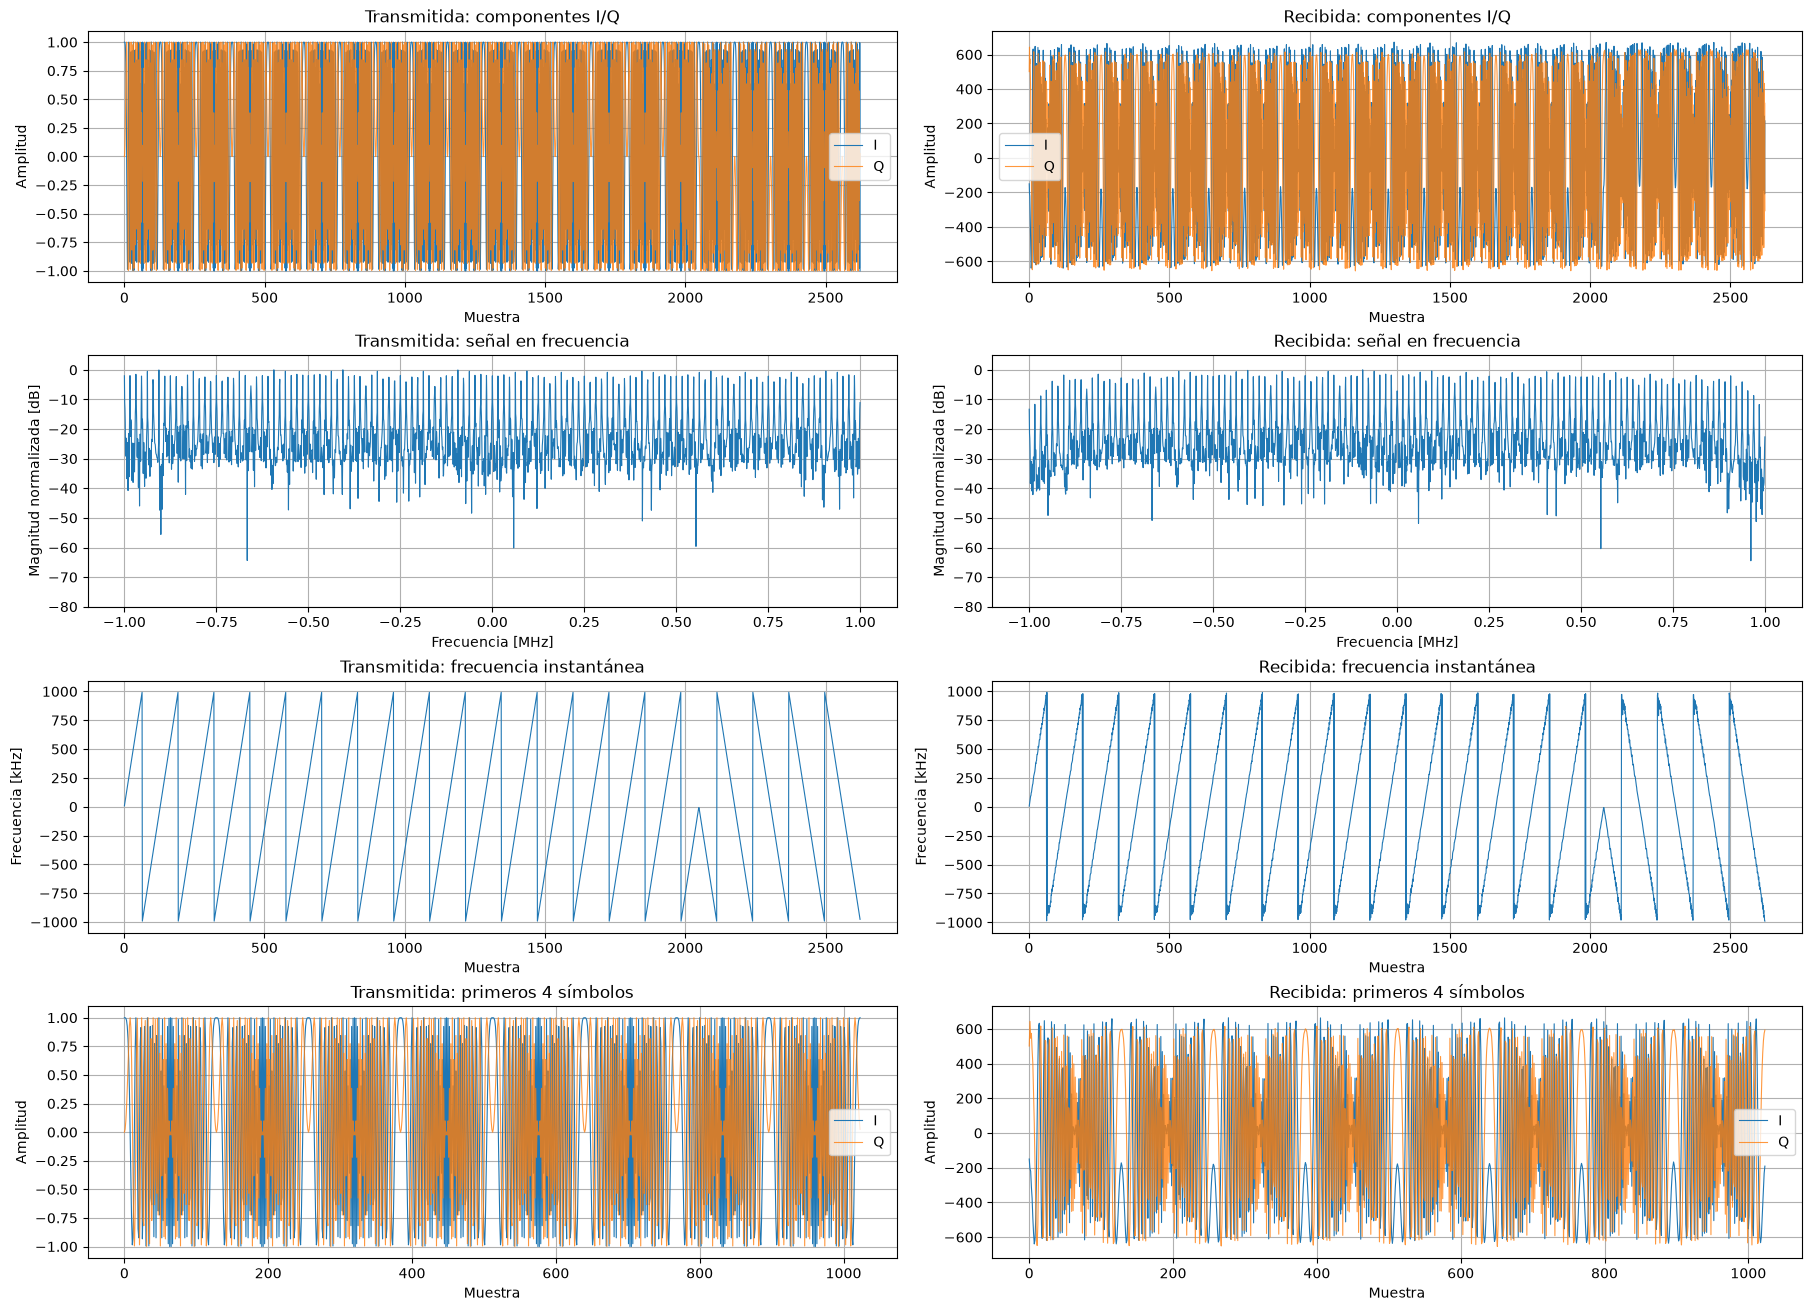

In [15]:
def graficar_preambulo_lora(tx, rx, fs, inicio=0, n_muestras=0):
    if n_muestras <= 0:
        n_muestras = min(len(tx), len(rx) - inicio)
    tx_vista = np.asarray(tx[:n_muestras], dtype=complex)
    rx_vista = np.asarray(rx[inicio:inicio + n_muestras], dtype=complex)
    n_fft = max(len(tx_vista), len(rx_vista))
    frecuencia = np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / fs)) / 1e6

    fig, ax = plt.subplots(4, 2, figsize=(18, 13), constrained_layout=True)
    señales = ((tx_vista, 'Transmitida'), (rx_vista, 'Recibida'))
    for columna, (senal, etiqueta) in enumerate(señales):
        muestras = np.arange(len(senal))
        ax[0, columna].plot(muestras, np.real(senal), label='I', linewidth=0.8)
        ax[0, columna].plot(muestras, np.imag(senal), label='Q', linewidth=0.8, alpha=0.8)
        ax[0, columna].set_title(f'{etiqueta}: componentes I/Q')
        ax[0, columna].set_xlabel('Muestra')
        ax[0, columna].set_ylabel('Amplitud')
        ax[0, columna].legend()
        ax[0, columna].grid()

        espectro = np.fft.fftshift(np.fft.fft(senal, n=n_fft))
        magnitud = np.abs(espectro)
        espectro_db = 20 * np.log10(magnitud / (np.max(magnitud) + np.finfo(float).eps) + np.finfo(float).eps)
        ax[1, columna].plot(frecuencia, espectro_db, linewidth=0.8)
        ax[1, columna].set_title(f'{etiqueta}: señal en frecuencia')
        ax[1, columna].set_xlabel('Frecuencia [MHz]')
        ax[1, columna].set_ylabel('Magnitud normalizada [dB]')
        ax[1, columna].set_ylim(-80, 5)
        ax[1, columna].grid()

        fase = np.unwrap(np.angle(senal))
        frecuencia_instantanea = np.diff(fase) * fs / (2 * np.pi)
        ax[2, columna].plot(muestras[1:], frecuencia_instantanea / 1e3, linewidth=0.8)
        ax[2, columna].set_title(f'{etiqueta}: frecuencia instantánea')
        ax[2, columna].set_xlabel('Muestra')
        ax[2, columna].set_ylabel('Frecuencia [kHz]')
        ax[2, columna].grid()

        n_primeros = min(len(muestras), 4 * N_LORA)
        ax[3, columna].plot(muestras[:n_primeros], np.real(senal[:n_primeros]), label='I', linewidth=0.8)
        ax[3, columna].plot(muestras[:n_primeros], np.imag(senal[:n_primeros]), label='Q', linewidth=0.8, alpha=0.8)
        ax[3, columna].set_title(f'{etiqueta}: primeros 4 símbolos')
        ax[3, columna].set_xlabel('Muestra')
        ax[3, columna].set_ylabel('Amplitud')
        ax[3, columna].legend()
        ax[3, columna].grid()
    plt.show()

graficar_preambulo_lora(
    tx_signal[N_LORA:N_LORA + len(tx_preamble)],
    rx_signal,
    FS_LORA,
    inicio=inicio_rx if comparacion is not None else 0,
    n_muestras=len(tx_preamble),
)

## Correlaciones en toda la captura y detalle de la cabecera

Las curvas muestran qué se correlaciona en cada posición candidata. Los puntos marcan inicios detectados. En el detalle, las líneas verticales indican el comienzo de los upchirps, de los downchirps, del cuarto descendente y del payload. La curva de decisión es el mínimo entre las cuatro partes y la cabecera completa; el producto ordena los máximos vecinos. El umbral exploratorio es `0,45` y el fuerte es `0,80`; si la captura real no lo alcanza, las curvas permitirán ver cuál parte falla antes de ajustarlo.


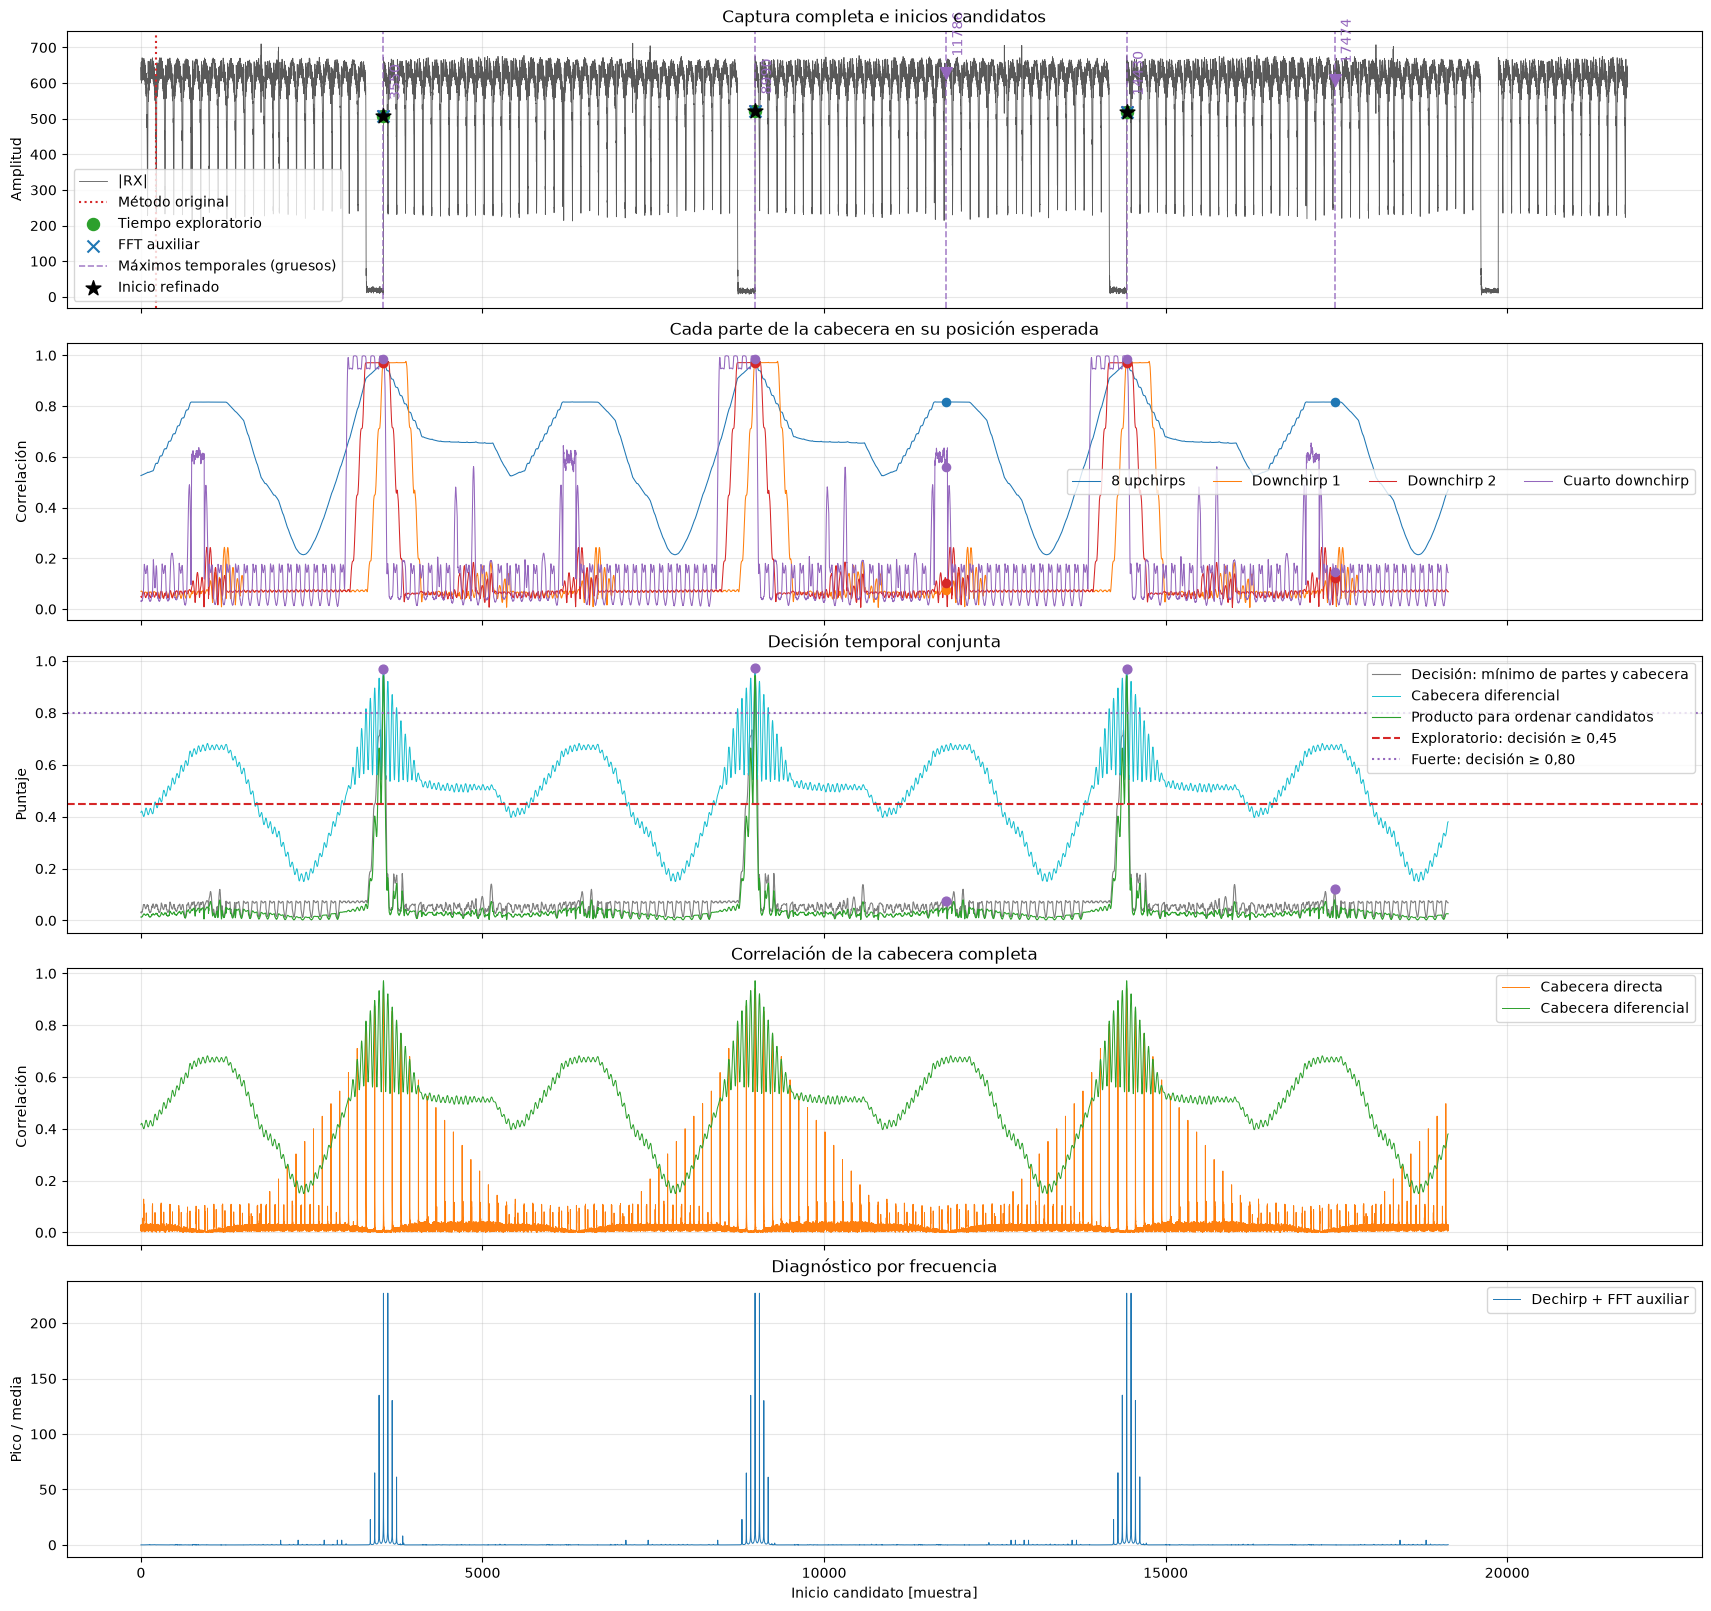

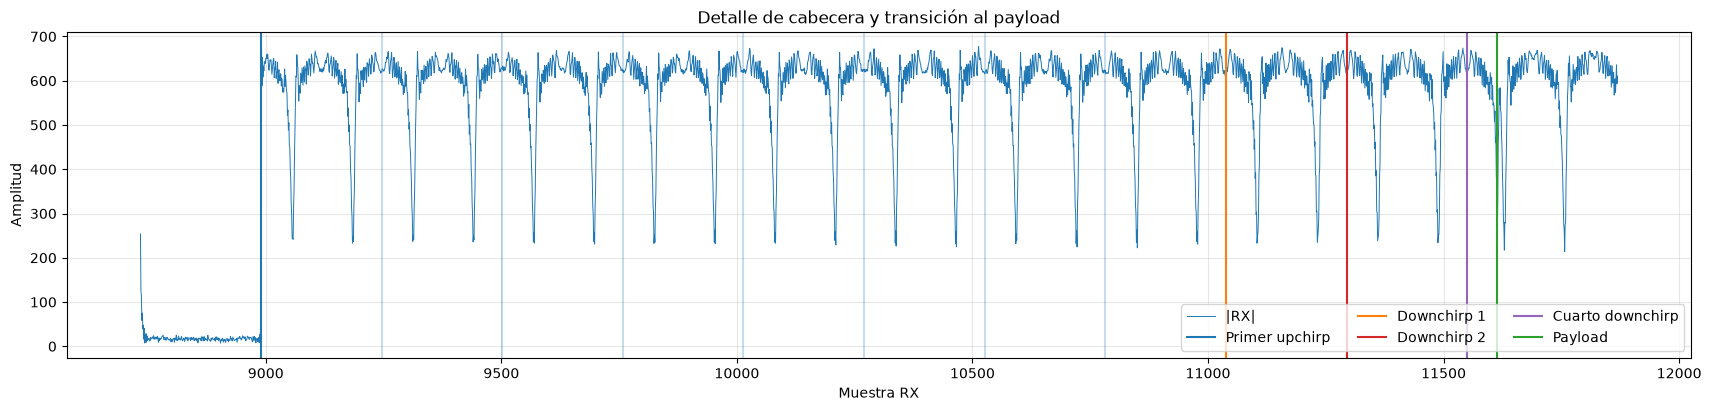

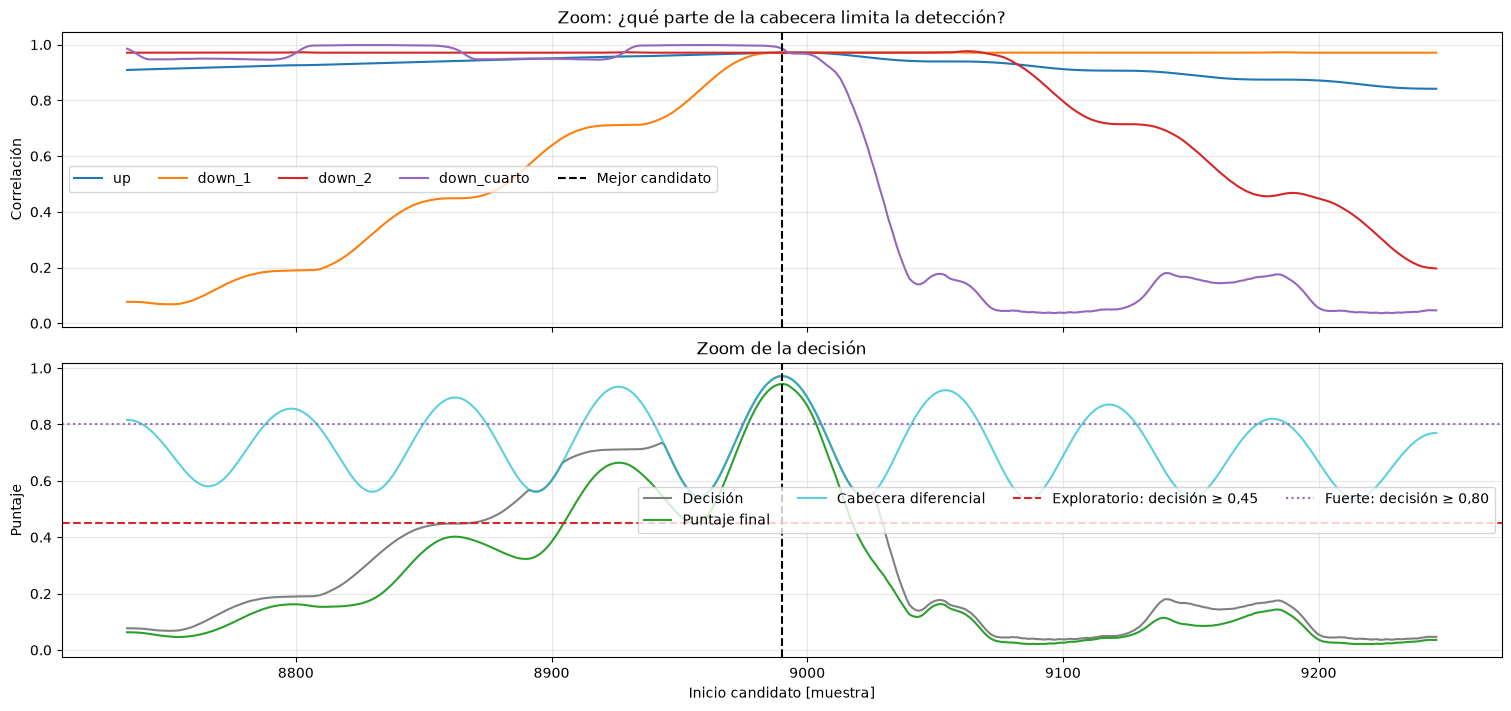

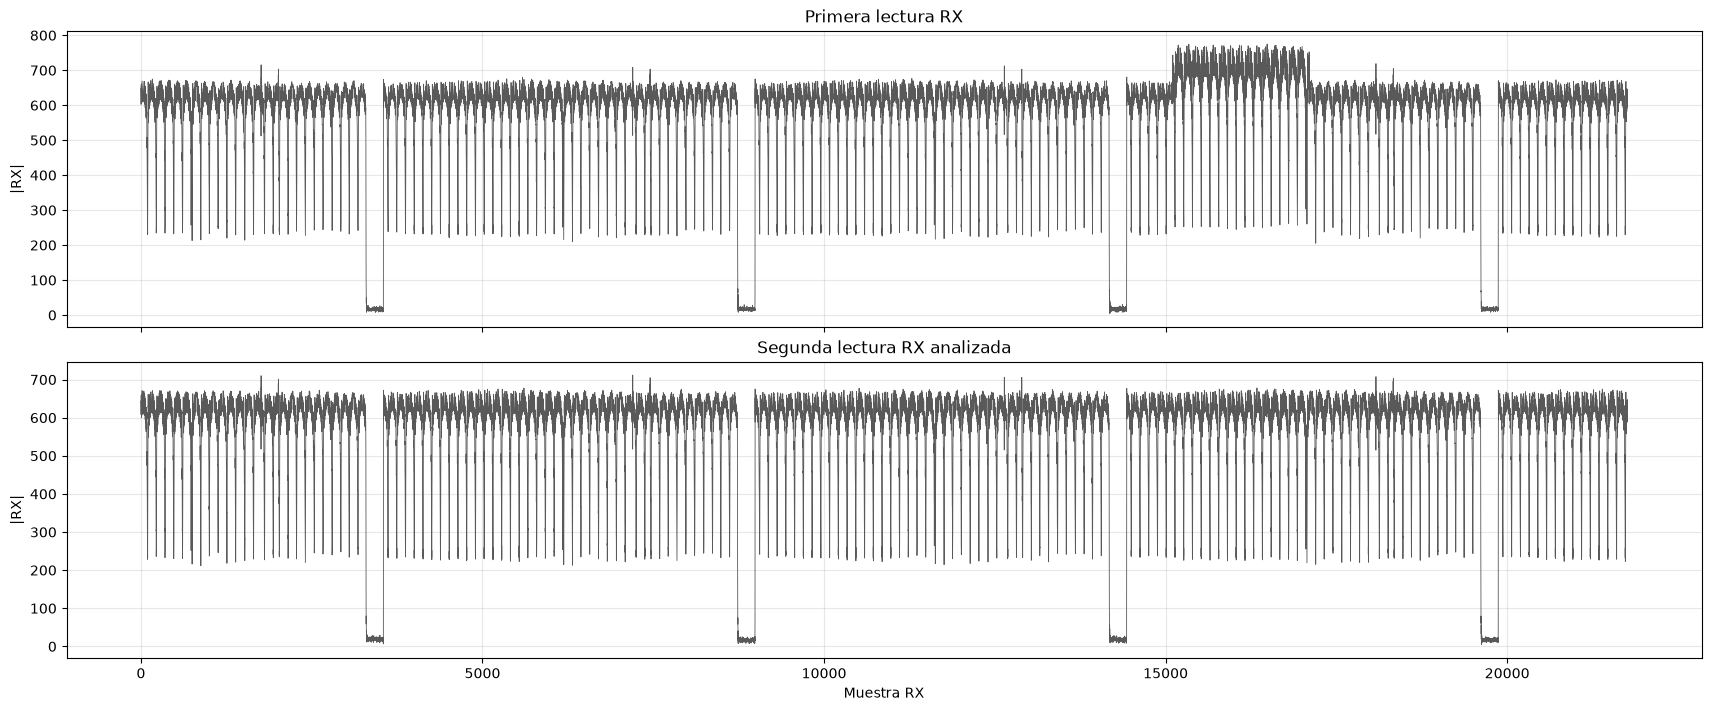

In [16]:
fig, ax = plt.subplots(5, 1, figsize=(17, 16), sharex=True, constrained_layout=True)
x = np.arange(len(rx_signal))
ax[0].plot(x, np.abs(rx_signal), lw=0.6, color='0.35', label='|RX|')
ax[0].axvline(resultado_original['inicio_muestra'], color='tab:red', ls=':', label='Método original')
for resultado, color, nombre, marca in [(resultado_tiempo, 'tab:green', 'Tiempo exploratorio', 'o'),
                                        (resultado_fft, 'tab:blue', 'FFT auxiliar', 'x')]:
    for j, inicio in enumerate(resultado['inicios']):
        ax[0].scatter(inicio, np.abs(rx_signal[inicio]), s=75, marker=marca,
                      color=color, zorder=4, label=nombre if j == 0 else None)
for j, inicio in enumerate(resultado_tiempo['candidatos_mayores']):
    ax[0].axvline(inicio, color='tab:purple', ls='--', lw=1.2, alpha=0.8,
                  label='Máximos temporales (gruesos)' if j == 0 else None)
    ax[0].scatter(inicio, np.abs(rx_signal[inicio]), color='tab:purple', marker='v',
                  s=70, zorder=3)
    ax[0].annotate(str(inicio), (inicio, np.abs(rx_signal[inicio])),
                   xytext=(4, 14), textcoords='offset points', color='tab:purple', rotation=90)
for j, inicio_grueso in enumerate(resultado_tiempo['confirmados']):
    inicio_fino = refinar_inicio_directo(resultado_tiempo, inicio_grueso)
    ax[0].scatter(inicio_fino, np.abs(rx_signal[inicio_fino]), color='black', marker='*',
                  s=125, zorder=5, label='Inicio refinado' if j == 0 else None)
ax[0].set(ylabel='Amplitud', title='Captura completa e inicios candidatos')
ax[0].legend()

for nombre, color, etiqueta in [('up', 'tab:blue', '8 upchirps'),
                                ('down_1', 'tab:orange', 'Downchirp 1'),
                                ('down_2', 'tab:red', 'Downchirp 2'),
                                ('down_cuarto', 'tab:purple', 'Cuarto downchirp')]:
    ax[1].plot(resultado_tiempo[nombre], lw=0.75, color=color, label=etiqueta)
    for inicio in resultado_tiempo['candidatos_mayores']:
        ax[1].scatter(inicio, resultado_tiempo[nombre][inicio], color=color, s=35, zorder=4)
ax[1].set(ylabel='Correlación', title='Cada parte de la cabecera en su posición esperada')
ax[1].legend(ncol=4)

ax[2].plot(resultado_tiempo['decision'], color='0.5', lw=0.8, label='Decisión: mínimo de partes y cabecera')
ax[2].plot(resultado_tiempo['diferencial'], color='tab:cyan', lw=0.7, label='Cabecera diferencial')
ax[2].plot(resultado_tiempo['puntaje_final'], color='tab:green', lw=0.8, label='Producto para ordenar candidatos')
ax[2].axhline(resultado_tiempo['umbral'], color='tab:red', ls='--', label='Exploratorio: decisión ≥ 0,45')
ax[2].axhline(resultado_tiempo['umbral_fuerte'], color='tab:purple', ls=':', label='Fuerte: decisión ≥ 0,80')
for inicio in resultado_tiempo['candidatos_mayores']:
    ax[2].scatter(inicio, resultado_tiempo['decision'][inicio], color='tab:purple', s=40, zorder=4)
ax[2].set(ylabel='Puntaje', title='Decisión temporal conjunta')
ax[2].legend()

ax[3].plot(resultado_tiempo['directa'], lw=0.7, color='tab:orange', label='Cabecera directa')
ax[3].plot(resultado_tiempo['diferencial'], lw=0.7, color='tab:green', label='Cabecera diferencial')
ax[3].set(ylabel='Correlación', title='Correlación de la cabecera completa')
ax[3].legend()

ax[4].plot(resultado_fft['puntajes'], lw=0.7, color='tab:blue', label='Dechirp + FFT auxiliar')
ax[4].set(xlabel='Inicio candidato [muestra]', ylabel='Pico / media', title='Diagnóstico por frecuencia')
ax[4].legend()
for a in ax:
    a.grid(alpha=0.3)
plt.show()

if resultado_tiempo['candidatos_mayores']:
    inicio_zoom = refinar_inicio_directo(resultado_tiempo, resultado_tiempo['mejor_candidato'])
    ventana = slice(max(0, inicio_zoom - N_LORA),
                    min(len(rx_signal), inicio_zoom + len(tx_preamble) + N_LORA))
    fig, ax = plt.subplots(figsize=(17, 4), constrained_layout=True)
    ax.plot(x[ventana], np.abs(rx_signal[ventana]), lw=0.7, label='|RX|')
    ax.axvline(inicio_zoom, color='tab:blue', label='Primer upchirp')
    for j in range(1, 8):
        ax.axvline(inicio_zoom + j*N_LORA, color='tab:blue', alpha=0.25)
    ax.axvline(inicio_zoom + 8*N_LORA, color='tab:orange', label='Downchirp 1')
    ax.axvline(inicio_zoom + 9*N_LORA, color='tab:red', label='Downchirp 2')
    ax.axvline(inicio_zoom + 10*N_LORA, color='tab:purple', label='Cuarto downchirp')
    ax.axvline(inicio_zoom + len(tx_preamble), color='tab:green', label='Payload')
    ax.set(xlabel='Muestra RX', ylabel='Amplitud', title='Detalle de cabecera y transición al payload')
    ax.grid(alpha=0.3)
    ax.legend(ncol=3)
    plt.show()

# Este zoom se genera incluso cuando ningún puntaje supera el umbral.
centro = resultado_tiempo['mejor_candidato']
a = max(0, centro - N_LORA)
b = min(len(resultado_tiempo['combinada']), centro + N_LORA + 1)
fig, ax = plt.subplots(2, 1, figsize=(15, 7), sharex=True, constrained_layout=True)
for nombre, color in [('up', 'tab:blue'), ('down_1', 'tab:orange'),
                      ('down_2', 'tab:red'), ('down_cuarto', 'tab:purple')]:
    ax[0].plot(np.arange(a, b), resultado_tiempo[nombre][a:b], color=color, label=nombre)
ax[0].axvline(centro, color='black', ls='--', label='Mejor candidato')
ax[0].set(ylabel='Correlación', title='Zoom: ¿qué parte de la cabecera limita la detección?')
ax[0].legend(ncol=5)
ax[1].plot(np.arange(a, b), resultado_tiempo['decision'][a:b], color='0.5', label='Decisión')
ax[1].plot(np.arange(a, b), resultado_tiempo['puntaje_final'][a:b], color='tab:green', label='Puntaje final')
ax[1].plot(np.arange(a, b), resultado_tiempo['diferencial'][a:b], color='tab:cyan', alpha=0.7, label='Cabecera diferencial')
ax[1].axhline(resultado_tiempo['umbral'], color='tab:red', ls='--', label='Exploratorio: decisión ≥ 0,45')
ax[1].axhline(resultado_tiempo['umbral_fuerte'], color='tab:purple', ls=':', label='Fuerte: decisión ≥ 0,80')
ax[1].axvline(centro, color='black', ls='--')
ax[1].set(xlabel='Inicio candidato [muestra]', ylabel='Puntaje', title='Zoom de la decisión')
ax[1].legend(ncol=4)
for panel in ax:
    panel.grid(alpha=0.3)
plt.show()

# Comparación de la primera lectura con la segunda, ambas completas.
if 'rx_primera' in globals() and rx_primera is not None:
    fig, ax = plt.subplots(2, 1, figsize=(17, 7), sharex=True, constrained_layout=True)
    for panel, datos, etiqueta in zip(ax, (rx_primera, rx_signal),
                                       ('Primera lectura RX', 'Segunda lectura RX analizada')):
        panel.plot(np.abs(datos), color='0.35', lw=0.6)
        panel.set(ylabel='|RX|', title=etiqueta)
        panel.grid(alpha=0.3)
    ax[-1].set_xlabel('Muestra RX')
    plt.show()


## Comparación muestra a muestra y por símbolo

Sólo se grafica si la captura contiene una trama completa detectada. Se compara la forma de onda después de compensar frecuencia y ganancia compleja. Los puntos por símbolo muestran dónde se pierde parecido; la comparación exacta del mensaje se hace con los **bytes RX**, impresos arriba.


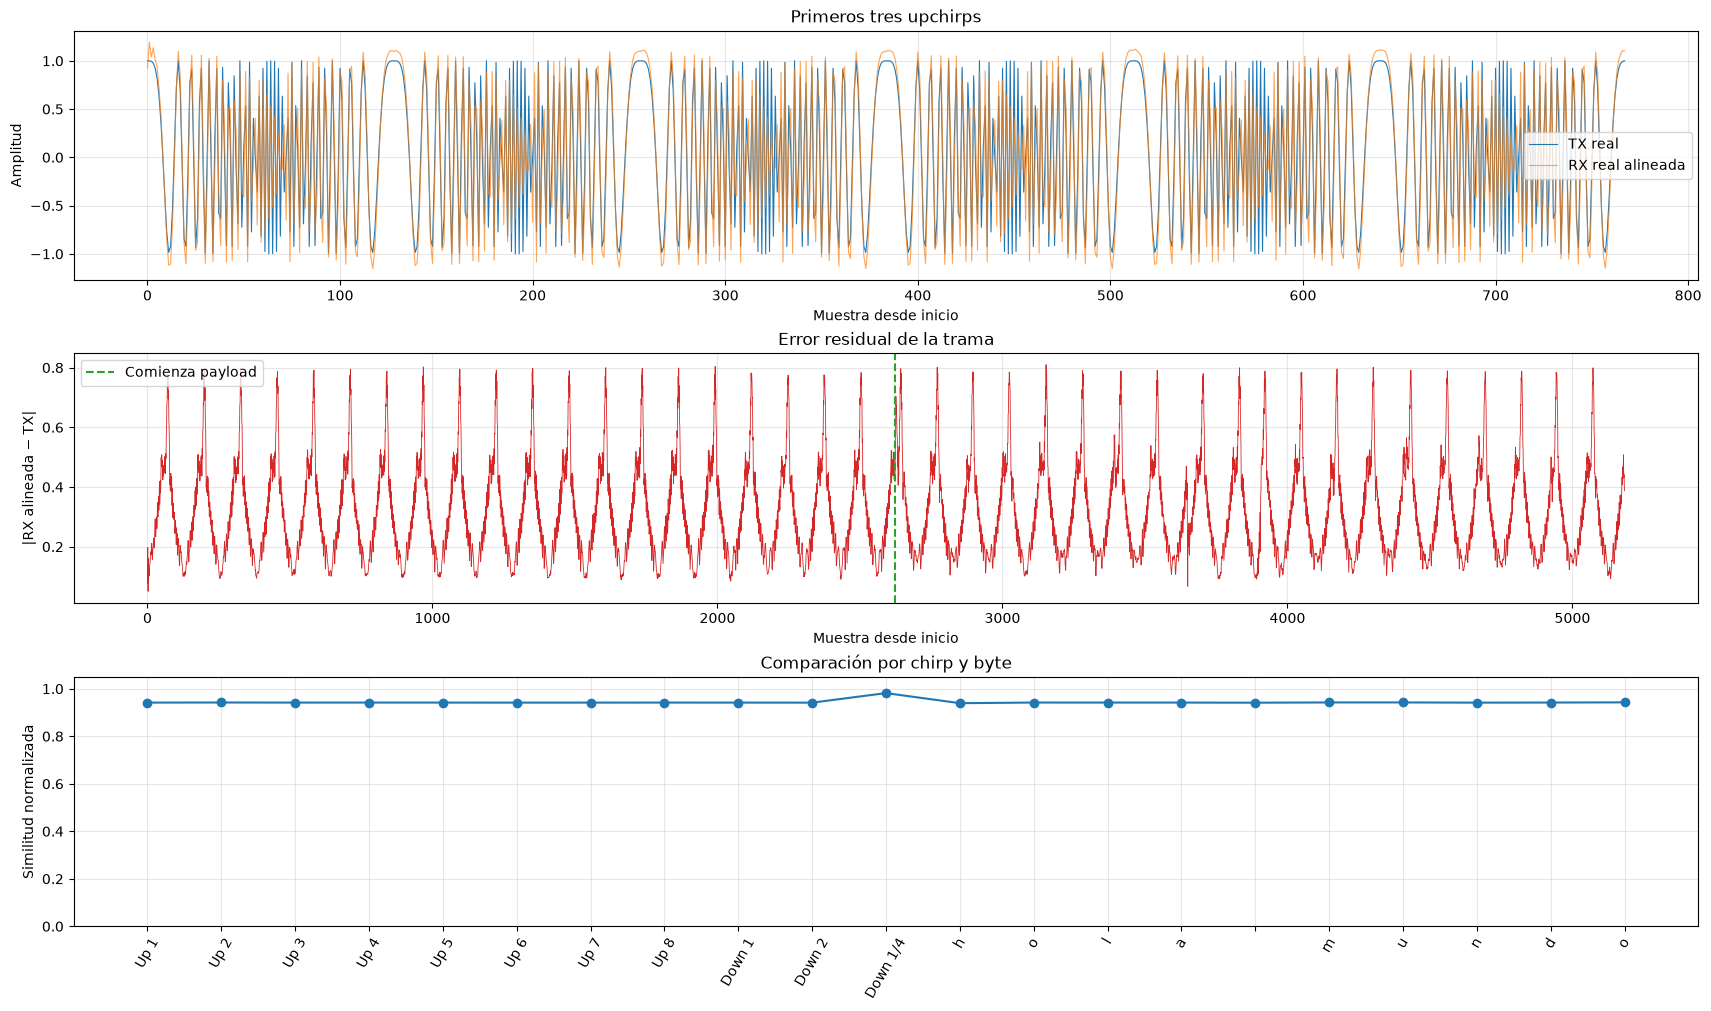

In [17]:
if comparacion is not None:
    tx = comparacion['tx']
    rx = comparacion['rx']
    error = comparacion['error']
    secciones = [(f'Up {j+1}', j*N_LORA, (j+1)*N_LORA) for j in range(8)]
    secciones += [('Down 1', 8*N_LORA, 9*N_LORA),
                  ('Down 2', 9*N_LORA, 10*N_LORA),
                  ('Down 1/4', 10*N_LORA, len(tx_preamble))]
    secciones += [(f'{chr(valor)}', len(tx_preamble)+j*N_LORA,
                   len(tx_preamble)+(j+1)*N_LORA) for j, valor in enumerate(bytes_enviados)]
    calidad = [abs(np.vdot(tx[a:b], rx[a:b])) / (np.linalg.norm(tx[a:b]) * np.linalg.norm(rx[a:b]))
               for _, a, b in secciones]
    fig, ax = plt.subplots(3, 1, figsize=(17, 10), constrained_layout=True)
    vista = min(3*N_LORA, len(tx))
    ax[0].plot(np.real(tx[:vista]), lw=0.8, label='TX real')
    ax[0].plot(np.real(rx[:vista]), lw=0.8, alpha=0.7, label='RX real alineada')
    ax[0].set(xlabel='Muestra desde inicio', ylabel='Amplitud', title='Primeros tres upchirps')
    ax[0].legend()
    ax[1].plot(np.abs(error), lw=0.6, color='tab:red')
    ax[1].axvline(len(tx_preamble), color='tab:green', ls='--', label='Comienza payload')
    ax[1].set(xlabel='Muestra desde inicio', ylabel='|RX alineada − TX|', title='Error residual de la trama')
    ax[1].legend()
    ax[2].plot(np.arange(len(calidad)), calidad, 'o-', color='tab:blue')
    ax[2].set_xticks(np.arange(len(calidad)), [nombre for nombre, _, _ in secciones], rotation=60)
    ax[2].set(ylabel='Similitud normalizada', ylim=(0, 1.05), title='Comparación por chirp y byte')
    for a in ax:
        a.grid(alpha=0.3)
    plt.show()
else:
    print('Comparación de TX/RX pendiente: no se detectó una trama completa.')


## Qué demuestra la captura real del 16/11/2026

Se conserva aquí el análisis de la corrida **anterior** a corregir el buffer TX. El RX de 10.880 muestras contiene ocho repeticiones de un bloque de 1360 muestras. Ese bloque coincide con el **prefijo** de TX (similitud IQ ≈ 0,93), que contiene silencio y los primeros upchirps. El primer downchirp empieza recién después de la muestra TX 2304, y el payload después de 2880: ninguno entra en el bloque repetido. Por ello los máximos débiles de 1944, 4668 y 7829 **no son comienzos de tramas completas**. Las dos capturas guardadas, antes y después de escalar el preámbulo por `1/√N`, muestran el mismo período de 1360 muestras.

La primera lectura RX no permite concluir nada sobre un transitorio en el primer ciclo: empezó a mitad de la transmisión cíclica y la señal enviada ya estaba truncada. La nueva corrida guarda una primera lectura y una segunda de análisis, ambas de cuatro períodos.


Captura real previa: 10880 muestras RX; 5440 muestras TX esperadas
Período medido en RX: 1360 muestras; primer silencio: 1021
Similitud IQ del prefijo TX con un período RX: 0.932
Primer downchirp previsto en TX: 2048 muestras después del silencio;
el bloque realmente repetido termina en: 1360
Máximos temporales (muestra, curva de decisión): [(1944, 0.09), (7829, 0.09), (4668, 0.075)]


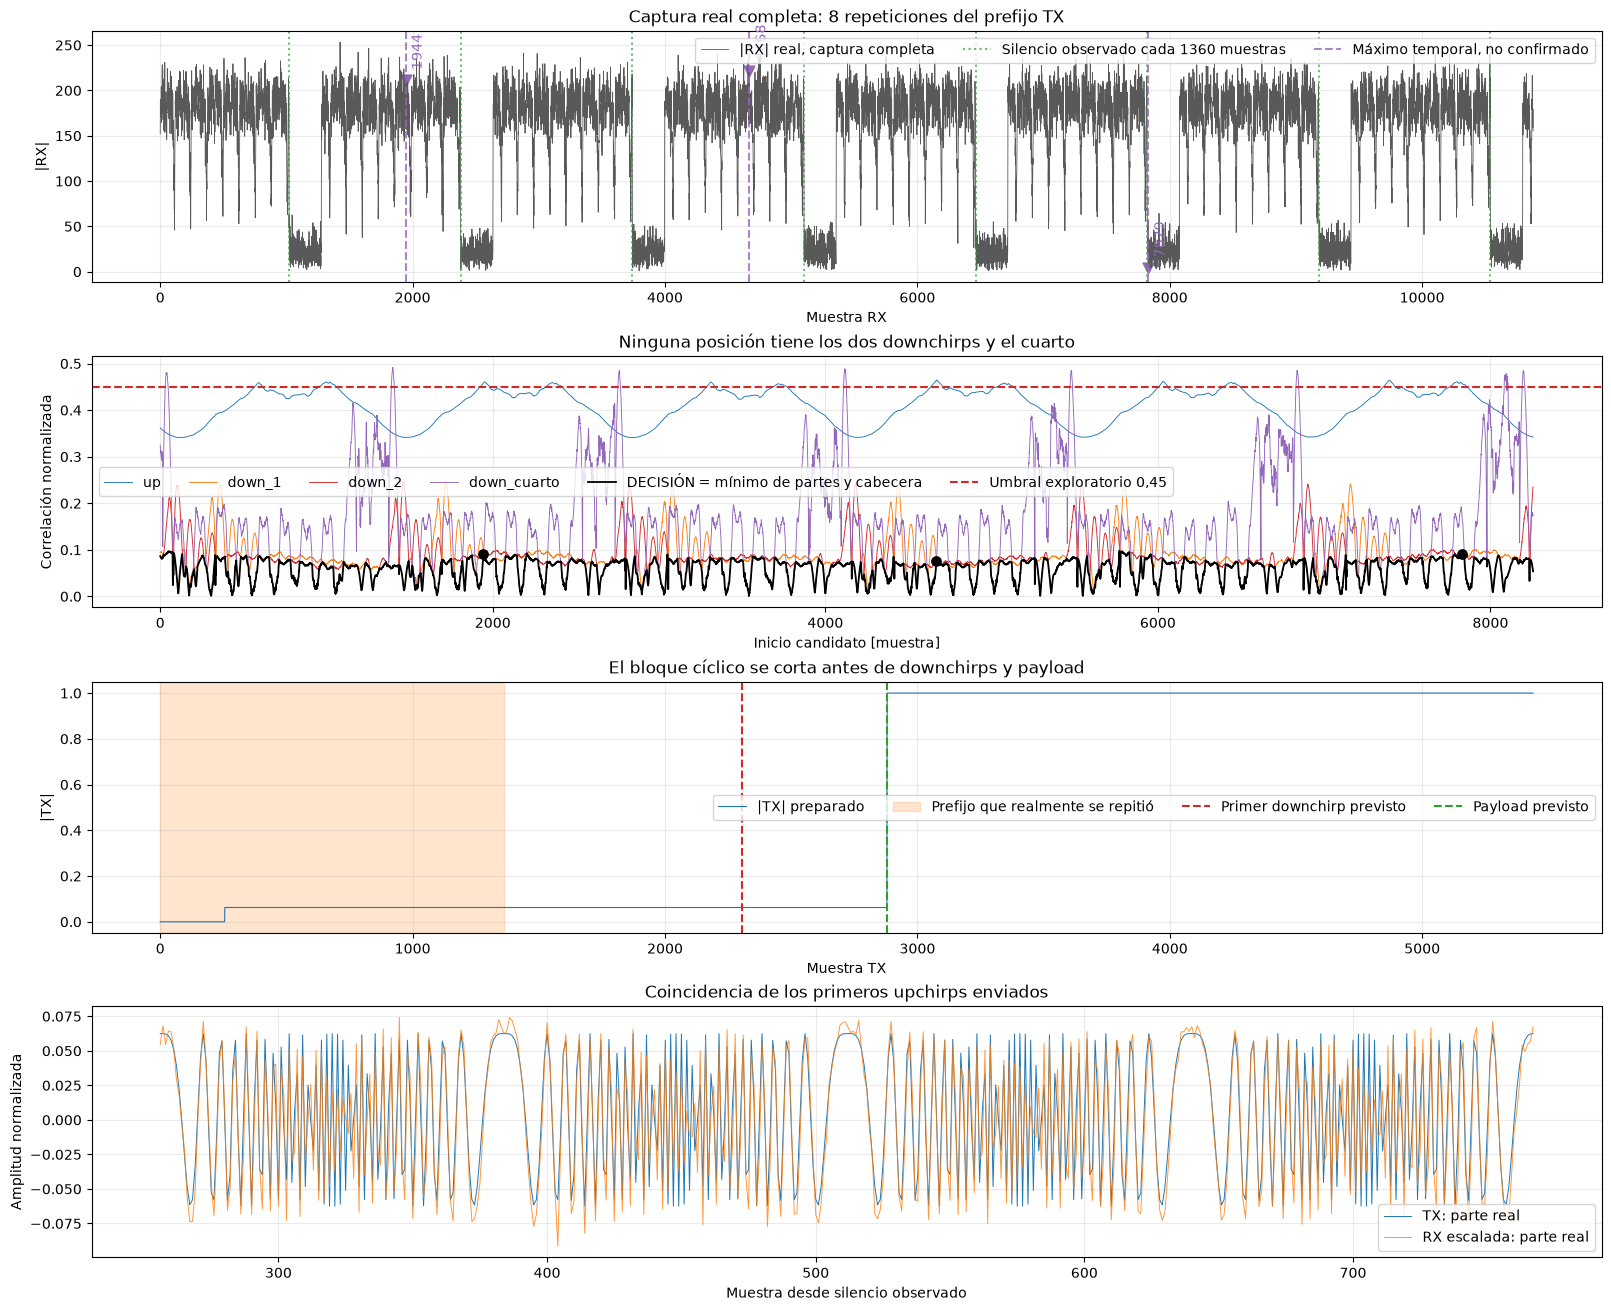

In [18]:
# Diagnóstico reproducible de la captura real anterior al arreglo del buffer TX.
archivo_anterior = Path('sdr_final/captura_chesta_20261116T005600_823650Z.npz')
if not archivo_anterior.exists():
    archivo_anterior = Path('captura_chesta_20261116T005600_823650Z.npz')
if archivo_anterior.exists():
    with np.load(archivo_anterior) as datos_anteriores:
        rx_anterior = datos_anteriores['rx_signal']
        tx_anterior = datos_anteriores['tx_signal']
    resultado_anterior = detectar_por_tiempo(rx_anterior, tx_preamble, N_LORA)
    envolvente = np.abs(rx_anterior)
    autocorr = correlate(envolvente - envolvente.mean(),
                         envolvente - envolvente.mean(), mode='full', method='fft')[len(envolvente)-1:]
    periodo_observado = int(1000 + np.argmax(autocorr[1000:2000]))
    energia_ventana = np.convolve(envolvente**2, np.ones(N_LORA), mode='valid')
    primer_silencio = int(np.argmin(energia_ventana[:periodo_observado]))
    silencios_observados = np.arange(primer_silencio, len(rx_anterior), periodo_observado)
    prefijo = tx_anterior[:periodo_observado]
    segmento = rx_anterior[primer_silencio:primer_silencio+periodo_observado]
    activo = np.abs(prefijo) > 0.03
    similitud_prefijo = abs(np.vdot(prefijo[activo], segmento[activo])) / (
        np.linalg.norm(prefijo[activo]) * np.linalg.norm(segmento[activo]))
    print('Captura real previa:', len(rx_anterior), 'muestras RX;', len(tx_anterior), 'muestras TX esperadas')
    print('Período medido en RX:', periodo_observado, 'muestras; primer silencio:', primer_silencio)
    print('Similitud IQ del prefijo TX con un período RX:', round(float(similitud_prefijo), 3))
    print('Primer downchirp previsto en TX:', 8*N_LORA, 'muestras después del silencio;')
    print('el bloque realmente repetido termina en:', periodo_observado)
    print('Máximos temporales (muestra, curva de decisión):',
          [(i, round(float(resultado_anterior['decision'][i]), 3))
           for i in resultado_anterior['candidatos_mayores']])

    fig, ax = plt.subplots(4, 1, figsize=(16, 13), constrained_layout=True)
    ax[0].plot(envolvente, color='0.35', lw=0.6, label='|RX| real, captura completa')
    for j, inicio in enumerate(silencios_observados):
        ax[0].axvline(inicio, color='tab:green', ls=':', alpha=0.7,
                      label='Silencio observado cada 1360 muestras' if j == 0 else None)
    for j, inicio in enumerate(resultado_anterior['candidatos_mayores']):
        ax[0].axvline(inicio, color='tab:purple', ls='--', alpha=0.8,
                      label='Máximo temporal, no confirmado' if j == 0 else None)
        ax[0].scatter(inicio, envolvente[inicio], color='tab:purple', marker='v', s=60)
        ax[0].annotate(str(inicio), (inicio, envolvente[inicio]), xytext=(4, 10),
                       textcoords='offset points', rotation=90, color='tab:purple')
    ax[0].set(xlabel='Muestra RX', ylabel='|RX|', title='Captura real completa: 8 repeticiones del prefijo TX')
    ax[0].legend(ncol=3)

    for nombre, color in [('up', 'tab:blue'), ('down_1', 'tab:orange'),
                          ('down_2', 'tab:red'), ('down_cuarto', 'tab:purple')]:
        ax[1].plot(resultado_anterior[nombre], color=color, lw=0.65, label=nombre)
    ax[1].plot(resultado_anterior['decision'], color='black', lw=1.3,
               label='DECISIÓN = mínimo de partes y cabecera')
    ax[1].axhline(0.45, color='tab:red', ls='--', label='Umbral exploratorio 0,45')
    for inicio in resultado_anterior['candidatos_mayores']:
        ax[1].scatter(inicio, resultado_anterior['decision'][inicio], color='black', s=45, zorder=4)
    ax[1].set(xlabel='Inicio candidato [muestra]', ylabel='Correlación normalizada',
              title='Ninguna posición tiene los dos downchirps y el cuarto')
    ax[1].legend(ncol=6)

    ax[2].plot(abs(tx_anterior), color='tab:blue', lw=0.8, label='|TX| preparado')
    ax[2].axvspan(0, periodo_observado, color='tab:orange', alpha=0.2,
                  label='Prefijo que realmente se repitió')
    ax[2].axvline(8*N_LORA + N_LORA, color='tab:red', ls='--', label='Primer downchirp previsto')
    ax[2].axvline(N_LORA+len(tx_preamble), color='tab:green', ls='--', label='Payload previsto')
    ax[2].set(xlabel='Muestra TX', ylabel='|TX|',
              title='El bloque cíclico se corta antes de downchirps y payload')
    ax[2].legend(ncol=4)

    ganancia_prefijo = np.vdot(prefijo[activo], segmento[activo]) / np.vdot(prefijo[activo], prefijo[activo])
    segmento_alineado = segmento / ganancia_prefijo
    vista = slice(N_LORA, 3*N_LORA)
    ax[3].plot(np.arange(N_LORA, 3*N_LORA), np.real(prefijo[vista]),
               color='tab:blue', lw=0.7, label='TX: parte real')
    ax[3].plot(np.arange(N_LORA, 3*N_LORA), np.real(segmento_alineado[vista]),
               color='tab:orange', lw=0.7, alpha=0.8, label='RX escalada: parte real')
    ax[3].set(xlabel='Muestra desde silencio observado', ylabel='Amplitud normalizada',
              title='Coincidencia de los primeros upchirps enviados')
    ax[3].legend()
    for panel in ax:
        panel.grid(alpha=0.25)
    plt.show()
else:
    print('Captura IQ previa no encontrada; la figura de esta celda muestra el diagnóstico guardado.')
